# 01 — EDA and statistics

This notebook finds the defects in the raw panel, applies the cleaning contract, and then runs eight
exploratory passes. It produces the two things later notebooks depend on: the **per-horizon admissible
lag sets** and **five testable predictions**.

**Inputs:** `data/processed/panel_raw.parquet` (notebook 00).
**Outputs:** `data/processed/panel.parquet` (cleaned, with `net_load`, `renewable_share`, `ramp`), ledger block
`results.json:nb01`, and figures `01_*.png` in `reports/figures/`.

### 0.1 — Setup and load the RAW panel

Read the untouched `panel_raw.parquet`, so every defect below is real evidence. The row count should be
315,648, and there is no `net_load` column yet.

In [1]:
import sys, json, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import config as cfg
from src import results as R

pd.set_option("display.width", 160, "display.max_columns", 60)
plt.rcParams["figure.figsize"] = cfg.FIGSIZE
plt.rcParams["figure.dpi"] = cfg.DPI
np.random.seed(cfg.SEED)

# Notebook 00's artefact: the raw join, exactly as the two APIs served it.
raw = pd.read_parquet(cfg.PANEL_RAW)
raw[cfg.TIME_COL] = pd.to_datetime(raw[cfg.TIME_COL])
zones = sorted(raw[cfg.GROUP_COL].unique())

nb00 = R.load().get("nb00", {})
print(f"raw panel : {len(raw):,} rows x {raw.shape[1]} columns")
print(f"source    : {nb00.get('source', '?')}   sha {nb00.get('panel_hash', '?')}")
print(f"span      : {raw[cfg.TIME_COL].min()} -> {raw[cfg.TIME_COL].max()} (UTC)")
print(f"zones     : {zones}")
print()
print("NOTE: there is deliberately no `net_load` column yet -- it is derived in 0.5,")
print("      after the cleaning contract has been applied and justified.")
raw.head(3)

raw panel : 315,648 rows x 32 columns
source    : eia930+open-meteo   sha 88e12050c751419c
span      : 2019-01-01 00:00:00 -> 2024-12-31 23:00:00 (UTC)
zones     : ['BPAT', 'CISO', 'ERCO', 'MISO', 'NYIS', 'SWPP']

NOTE: there is deliberately no `net_load` column yet -- it is derived in 0.5,
      after the cleaning contract has been applied and justified.


,timestamp,demand,demand_forecast,net_generation,total_interchange,coal,gas,nuclear,oil,other,solar,hydro,wind,zone,battery,unknown_storage,solar_battery,temp,humidity,wind_speed,cloud_cover,ghi,dni_horiz,dhi,wind_speed_100m,wind_gust,apparent_temp,dew_point,snowfall,snow_depth,precipitation,pressure
0,2019-01-01,7026.0,7263.0,10660.0,8921.0,NaN,1447.0,1168.0,NaN,207.0,2.0,7761.0,17.0,BPAT,NaN,NaN,NaN,5.1,71,9.9,1,106.0,68.0,38.0,20.9,20.5,1.5,0.3,0.0,0.0,0.0,1027.6
1,2019-01-01,23216.0,22491.0,15042.0,-6138.0,9.0,6574.0,2273.0,88.0,-22.0,1222.0,2403.0,2497.0,CISO,NaN,NaN,NaN,15.3,49,9.2,1,203.0,148.0,55.0,12.2,27.7,12.6,4.5,0.0,0.0,0.0,999.9
2,2019-01-01,38397.0,37423.0,38197.0,-200.0,9400.0,19491.0,3915.0,NaN,26.0,161.0,189.0,5020.0,ERCO,NaN,NaN,NaN,9.8,73,11.9,80,10.0,3.0,7.0,13.4,13.7,6.8,5.2,0.0,0.0,0.0,997.2


## Pass 0 — Defects, and the cleaning contract

This pass writes `panel.parquet`. The contract has five rules, each argued from evidence below:

| rule | why |
|---|---|
| duplicate `(zone, hour)` rows keep the **last** | a duplicate is a revision |
| physically impossible values → **NaN** | they carry no information about the true value |
| negative `solar`, `wind`, `hydro`, `nuclear` → **clipped to 0** | a small negative is an accounting artefact (0.4) |
| interpolate runs of **≤ 3 hours** only | short gaps are dropouts; long gaps are outages |
| drop rows whose **target** cannot be recovered | losing 0.05% of rows is cheaper than training on invented ones |


### 0.2 — Missingness: how much, where, and is it systematic?

Missing share by column, then by zone and month. A solid band in the heatmap is a period (an outage or a
reporting change, which should not be interpolated); speckle is random dropout.

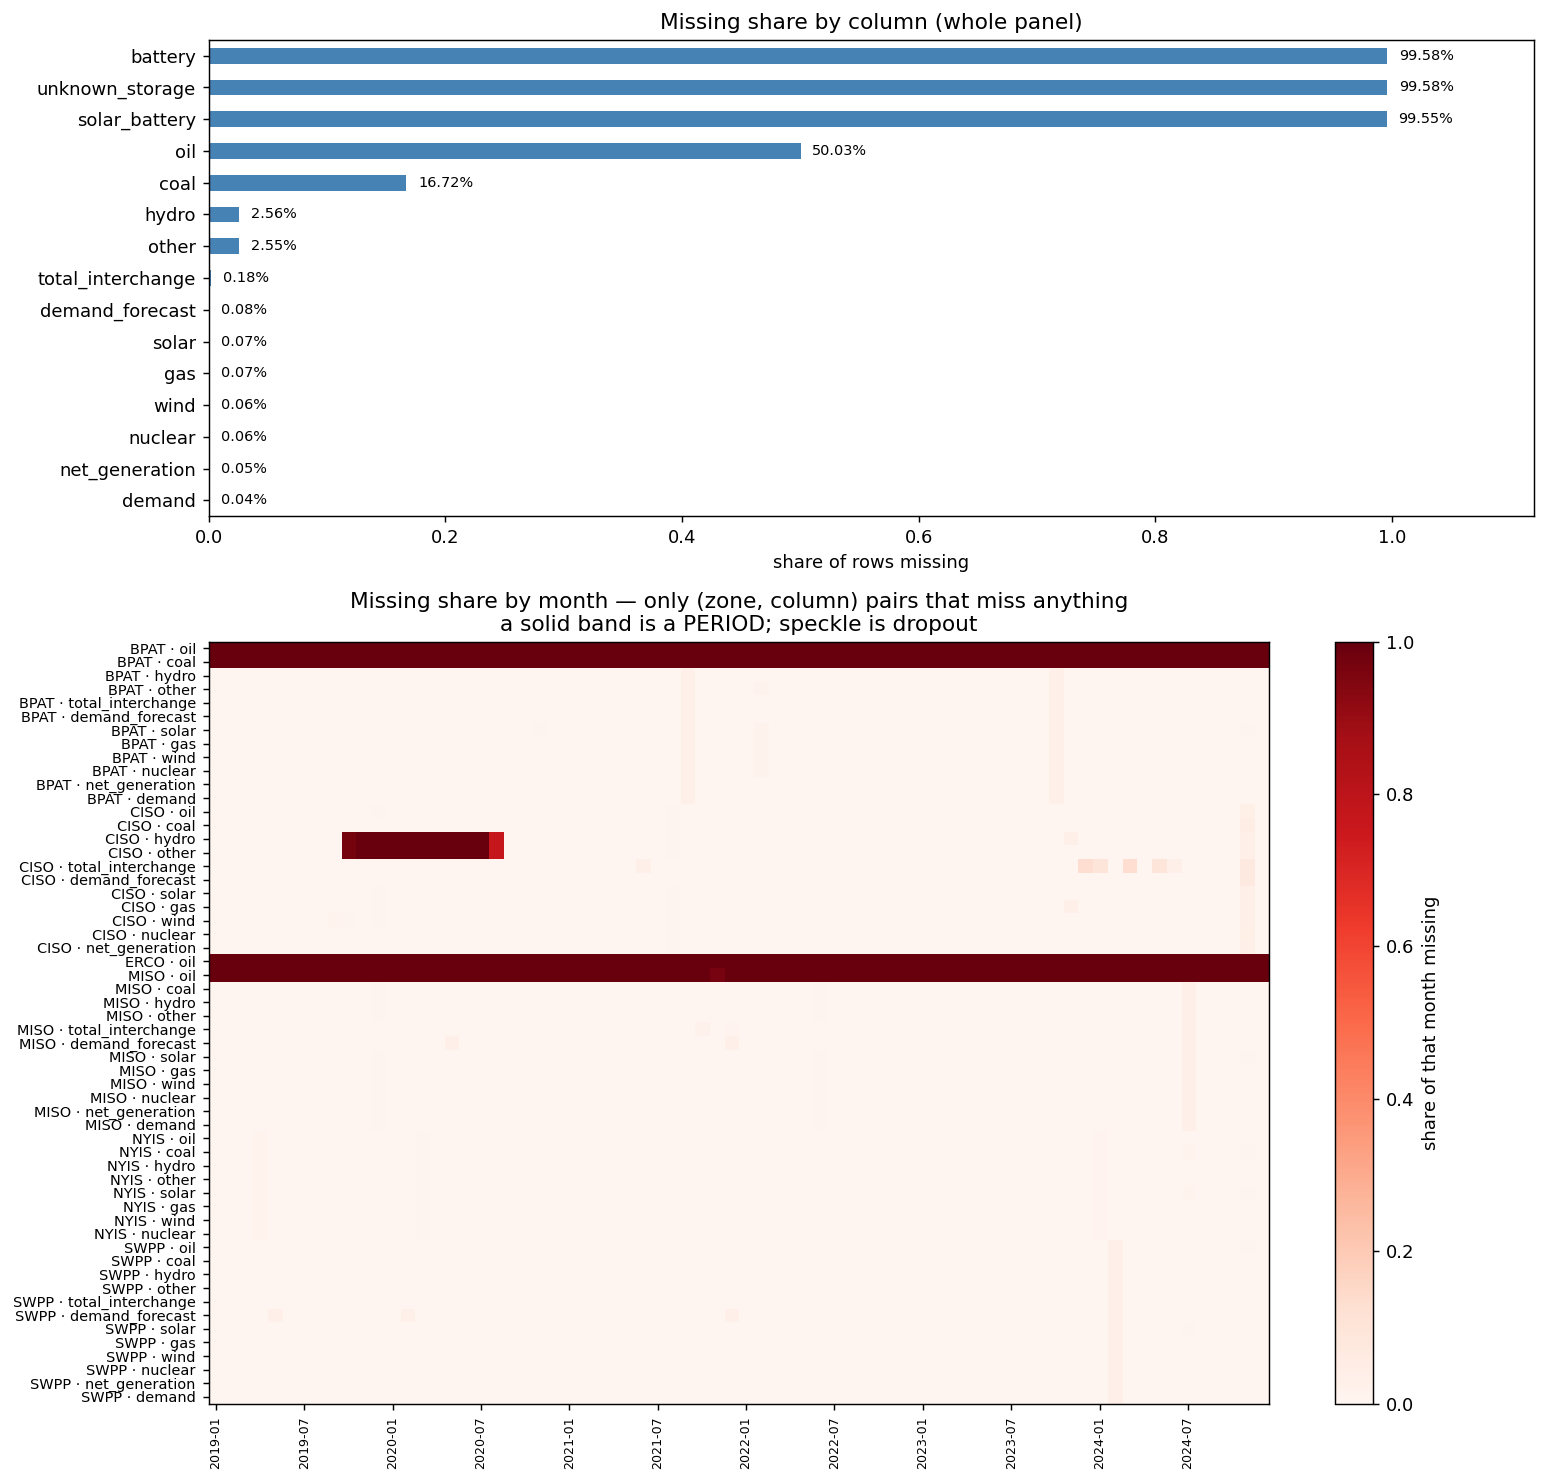

--- missing share by column, per zone (%) ---
      battery  unknown_storage  solar_battery     oil    coal  hydro  other  total_interchange  demand_forecast  solar   gas  wind  nuclear  net_generation  demand
zone                                                                                                                                                               
BPAT   100.00           100.00          97.33  100.00  100.00   0.09   0.11               0.10             0.09   0.14  0.11  0.11     0.12            0.09    0.09
CISO   100.00           100.00         100.00    0.10    0.11  15.08  15.04               0.82             0.09   0.10  0.14  0.12     0.09            0.08    0.05
ERCO    97.46            97.46         100.00  100.00    0.00   0.01   0.01               0.02             0.00   0.01  0.00  0.00     0.00            0.00    0.00
MISO   100.00           100.00         100.00   99.95    0.07   0.07   0.07               0.10             0.14   0.07  0.07  0.07    

In [2]:
# WHAT: missingness by column, then by (zone, column) over time.
# WHY:  the time structure is what licenses -- or forbids -- interpolation.
measure_cols = [c for c in raw.columns if c not in (cfg.TIME_COL, cfg.GROUP_COL)]
overall = raw[measure_cols].isna().mean().sort_values(ascending=False)
nz = overall[overall > 0]

d = raw.copy()
d["month"] = d[cfg.TIME_COL].dt.to_period("M")
all_months = sorted(d["month"].unique())

# Columns worth tracking over time: those missing something, but not the storage
# columns (99.6% absent purely because EIA began publishing them mid-window).
watch = [c for c in nz.index if nz[c] < 0.60]

rows, labels = [], []
for z in zones:
    g = d[d[cfg.GROUP_COL] == z]
    for c in watch:
        s = g.groupby("month")[c].apply(lambda x: x.isna().mean()).reindex(all_months)
        # > 1% of at least one month, not > 0: at zero the panel drew ~70
        # rows and its labels smeared into an unreadable strip. The rows
        # dropped here are single-hour speckle invisible at this scale; every
        # PERIOD band survives the cut.
        if s.fillna(0).max() > 0.01:
            rows.append(s.fillna(0).to_numpy())
            labels.append(f"{z} · {c}")

fig, axes = plt.subplots(2, 1, figsize=(12.0, 11.5), gridspec_kw={"height_ratios": [1, 1.6]})

nz.plot.barh(ax=axes[0], color="steelblue")
axes[0].invert_yaxis()
axes[0].set_xlabel("share of rows missing")
axes[0].set_title("Missing share by column (whole panel)")
for i, v in enumerate(nz.values):
    axes[0].text(v + .01, i, f"{100*v:.2f}%", va="center", fontsize=8)
axes[0].set_xlim(0, 1.12)

im = axes[1].imshow(np.array(rows), aspect="auto", cmap="Reds", vmin=0, vmax=1,
                    interpolation="nearest")
axes[1].set_yticks(range(len(labels)))
axes[1].set_yticklabels(labels, fontsize=8)
step = 6
axes[1].set_xticks(range(0, len(all_months), step))
axes[1].set_xticklabels([str(m) for m in all_months[::step]], rotation=90, fontsize=7)
axes[1].set_title("Missing share by month — only (zone, column) pairs that miss anything\n"
                  "a solid band is a PERIOD; speckle is dropout")
fig.colorbar(im, ax=axes[1], label="share of that month missing")
plt.tight_layout()
plt.savefig(cfg.FIGURES / "01_missingness.png", bbox_inches="tight")
plt.show()

miss_zone = raw.groupby(cfg.GROUP_COL)[list(nz.index)].apply(lambda g: g.isna().mean())
print("--- missing share by column, per zone (%) ---")
print((100 * miss_zone).round(2).to_string())
print("\n--- missing share by column, whole panel (%) ---")
print((100 * nz).round(3).to_string())

**Figure: `01_missingness.png` — missing share by column, and by (zone, column) over time.**

**What I see:** The three storage columns are about 99.6% missing, `oil` 50.03%, `coal` 16.72%, `hydro`
2.56%, `other` 2.55%, and everything else under 0.2%. `demand` is the best-covered EIA column at 0.04%; the
weather columns have no gaps. The heatmap shows full bands for `BPAT · oil`, `BPAT · coal`, `ERCO · oil` and
`MISO · oil`, and one block: `CISO · hydro` and `CISO · other`, missing from 2019-10 to 2020-08 (15.08% /
15.04% in the per-zone table).

**What it means:** Most of this is not missing data. BPAT does not burn oil, and EIA only started reporting
storage late in the window. The one real defect is the CISO block: two fuels stopped reporting for eleven
months and then resumed.

**What I do:** Never impute structural absence. The storage columns are not used. Same-hour `oil` is not a
feature; its lagged copy is median-imputed per fold. The CISO gap is recorded in `fuel_mix.ciso_gap_window`.
The target's source column is 99.96% present, so nothing downstream rests on imputed demand.

### 0.3 — Timeline integrity, and the runs of missing values

Two checks: is the hourly grid intact, and how long do runs of missing values last? Notebook 00 returned a
complete grid (52,608 rows per zone), so the defects are NaN runs inside rows, not missing timestamps. Run
length decides the repair: a 1–3 hour run is telemetry dropout and interpolation is close to the truth; a
day-long run is an outage, and filling it would invent a day of normal operation. EIA-930 periods are UTC,
so there are no DST repeats or skips.

--- (1) the hourly GRID ---


,rows,monotone,whole_hours,pct_steps_1h,missing_timestamps,repeated_hours
zone,,,,,,
BPAT,52608,True,True,100.0,0,0
CISO,52608,True,True,100.0,0,0
ERCO,52608,True,True,100.0,0,0
MISO,52608,True,True,100.0,0,0
NYIS,52608,True,True,100.0,0,0
SWPP,52608,True,True,100.0,0,0


duplicate (zone, timestamp) pairs across the whole raw panel : 0
-> the grid is intact and there is no repeated hour, which is the UTC claim
   tested rather than asserted. Every defect below is INSIDE a row.



--- (2) runs of consecutive missing `demand` (43 runs, 137 hours in total) ---

run-length distribution:
       n_runs  hours_total
hours                     
1          37           37
2           2            4
24          4           96

runs of <= 3 h are interpolated WHOLE; longer ones are dropped WHOLE.
  runs at or under the cap : 39  (41 hours, repaired)
  runs over the cap        : 4  (96 hours, dropped)

every run longer than 3 hours:
zone               start                 end  hours
BPAT 2021-09-15 08:00:00 2021-09-16 07:00:00     24
BPAT 2023-10-24 08:00:00 2023-10-25 07:00:00     24
MISO 2024-07-01 06:00:00 2024-07-02 05:00:00     24
SWPP 2024-02-20 07:00:00 2024-02-21 06:00:00     24


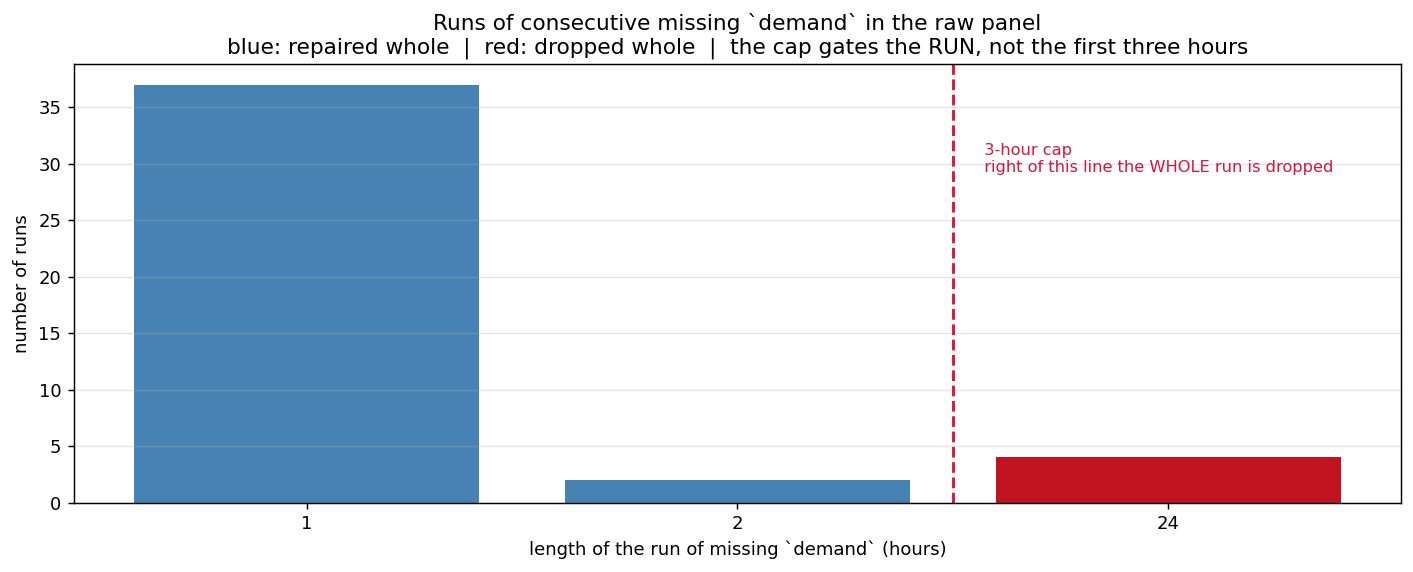

In [3]:
from src import data as data_loader

# WHAT: (1) is the hourly grid intact?  (2) how long do runs of missing `demand` last?
# WHY:  notebook 00 returned a COMPLETE grid, so the defect is not a missing timestamp -- it
#       is a present timestamp carrying a missing value. Measuring the wrong one reports
#       "no gaps" and silently loses the outages.
rows = []
for z, g in raw.groupby(cfg.GROUP_COL):
    ts = g[cfg.TIME_COL].sort_values()
    dt = ts.diff().dropna()
    rows.append({
        "zone": z, "rows": len(ts),
        "monotone": bool((dt > pd.Timedelta(0)).all()),
        "whole_hours": bool((dt % pd.Timedelta(hours=1) == pd.Timedelta(0)).all()),
        "pct_steps_1h": round(100 * float((dt == pd.Timedelta(hours=1)).mean()), 4),
        "missing_timestamps": int((dt > pd.Timedelta(hours=1)).sum()),
        "repeated_hours": int(ts.duplicated().sum()),
    })
grid = pd.DataFrame(rows).set_index("zone")
print("--- (1) the hourly GRID ---")
display(grid)

dup = int(raw.duplicated([cfg.GROUP_COL, cfg.TIME_COL]).sum())
print(f"duplicate (zone, timestamp) pairs across the whole raw panel : {dup}")
print("-> the grid is intact and there is no repeated hour, which is the UTC claim")
print("   tested rather than asserted. Every defect below is INSIDE a row.")


def missing_runs(s, times):
    """Start, end and length of each maximal run of NaN in `s`."""
    isna = s.isna().to_numpy()
    out, i, n = [], 0, len(isna)
    while i < n:
        if isna[i]:
            j = i
            while j + 1 < n and isna[j + 1]:
                j += 1
            out.append((times.iloc[i], times.iloc[j], j - i + 1))
            i = j + 1
        else:
            i += 1
    return out


runs = []
for z, g in raw.groupby(cfg.GROUP_COL):
    g = g.sort_values(cfg.TIME_COL)
    for start, end, length in missing_runs(g["demand"], g[cfg.TIME_COL]):
        runs.append({"zone": z, "start": start, "end": end, "hours": length})
runs = pd.DataFrame(runs)

print(f"\n--- (2) runs of consecutive missing `demand` ({len(runs)} runs, "
      f"{int(runs['hours'].sum()) if len(runs) else 0} hours in total) ---")
if len(runs):
    dist = (runs.groupby("hours").size().rename("n_runs").to_frame()
            .assign(hours_total=lambda d: d.index * d["n_runs"]))
    print("\nrun-length distribution:")
    print(dist.to_string())
    print(f"\nruns of <= {data_loader.MAX_INTERP_HOURS} h are interpolated WHOLE; "
          f"longer ones are dropped WHOLE.")
    print(f"  runs at or under the cap : {int((runs['hours'] <= data_loader.MAX_INTERP_HOURS).sum())}"
          f"  ({int(runs.loc[runs['hours'] <= data_loader.MAX_INTERP_HOURS, 'hours'].sum())} hours, repaired)")
    print(f"  runs over the cap        : {int((runs['hours'] > data_loader.MAX_INTERP_HOURS).sum())}"
          f"  ({int(runs.loc[runs['hours'] > data_loader.MAX_INTERP_HOURS, 'hours'].sum())} hours, dropped)")
    print("\nevery run longer than 3 hours:")
    print(runs[runs["hours"] > 3].sort_values("hours", ascending=False).to_string(index=False))

    fig, ax = plt.subplots(figsize=(11, 4.5))
    CAP = data_loader.MAX_INTERP_HOURS
    bars = ax.bar(dist.index.astype(str), dist["n_runs"],
                  color=["steelblue" if h <= CAP else "#c1121f" for h in dist.index])
    # THE CAP LINE, PLACED FROM THE DATA. It used to be hardcoded at x=2.5 on a
    # CATEGORICAL axis whose ticks are '1','2','24' at positions 0, 1, 2 -- so it
    # landed to the RIGHT of the 24-hour bar and read as though every run were
    # under the cap, which is the opposite of what the contract does. The boundary
    # is now computed: it sits between the last bar at or below the cap and the
    # first bar above it, whatever the run lengths turn out to be.
    n_under = int((dist.index <= CAP).sum())
    if 0 < n_under < len(dist):
        ax.axvline(n_under - 0.5, color="crimson", ls="--", lw=1.6)
        ax.text(n_under - 0.45, ax.get_ylim()[1] * .82,
                f"  {CAP}-hour cap\n  right of this line the WHOLE run is dropped",
                color="crimson", fontsize=9, va="top")
    ax.set_xlabel("length of the run of missing `demand` (hours)")
    ax.set_ylabel("number of runs")
    ax.set_title("Runs of consecutive missing `demand` in the raw panel\n"
                 "blue: repaired whole  |  red: dropped whole  |  "
                 "the cap gates the RUN, not the first three hours")
    ax.grid(axis="y", alpha=.3)
    plt.tight_layout()
    plt.savefig(cfg.FIGURES / "01_missing_runs.png", bbox_inches="tight")
    plt.show()

**Figure: `01_missing_runs.png` — how long the gaps in `demand` actually are.**

**What I see:** 43 runs, 137 missing hours: 37 runs of 1 hour, 2 of 2 hours, and 4 of exactly 24 hours
(BPAT 2021-09-15, BPAT 2023-10-24, MISO 2024-07-01, SWPP 2024-02-20). The 39 short runs (41 hours) are
interpolated; the four long ones (96 hours) are dropped. There are no duplicate (zone, timestamp) pairs.

**What it means:** The distribution is bimodal. The short runs are ordinary dropout. Each long run is
exactly 24 hours and starts between 06:00 and 08:00 UTC, which looks like a daily reporting cycle failing,
not a grid event.

**What I do:** The 3-hour cap is a gate on the whole run, not a fill limit: `interpolate_short_runs` in
`src/data.py` repairs a run only if it fits under the cap, per column. None of the 96 outage hours is
interpolated.

### 0.4 — Impossible values: negatives, and magnitudes that cannot be real

Two defects with different remedies. A small negative solar value is an accounting artefact, so clipping to
zero is close to the truth. A demand value far beyond any system peak says nothing about the true value, so
it becomes NaN. Such errors can hide: if demand and wind are inflated together, they cancel in
`net_load = demand − wind − solar`. The top panel uses a symlog axis because values run from 0 to millions.

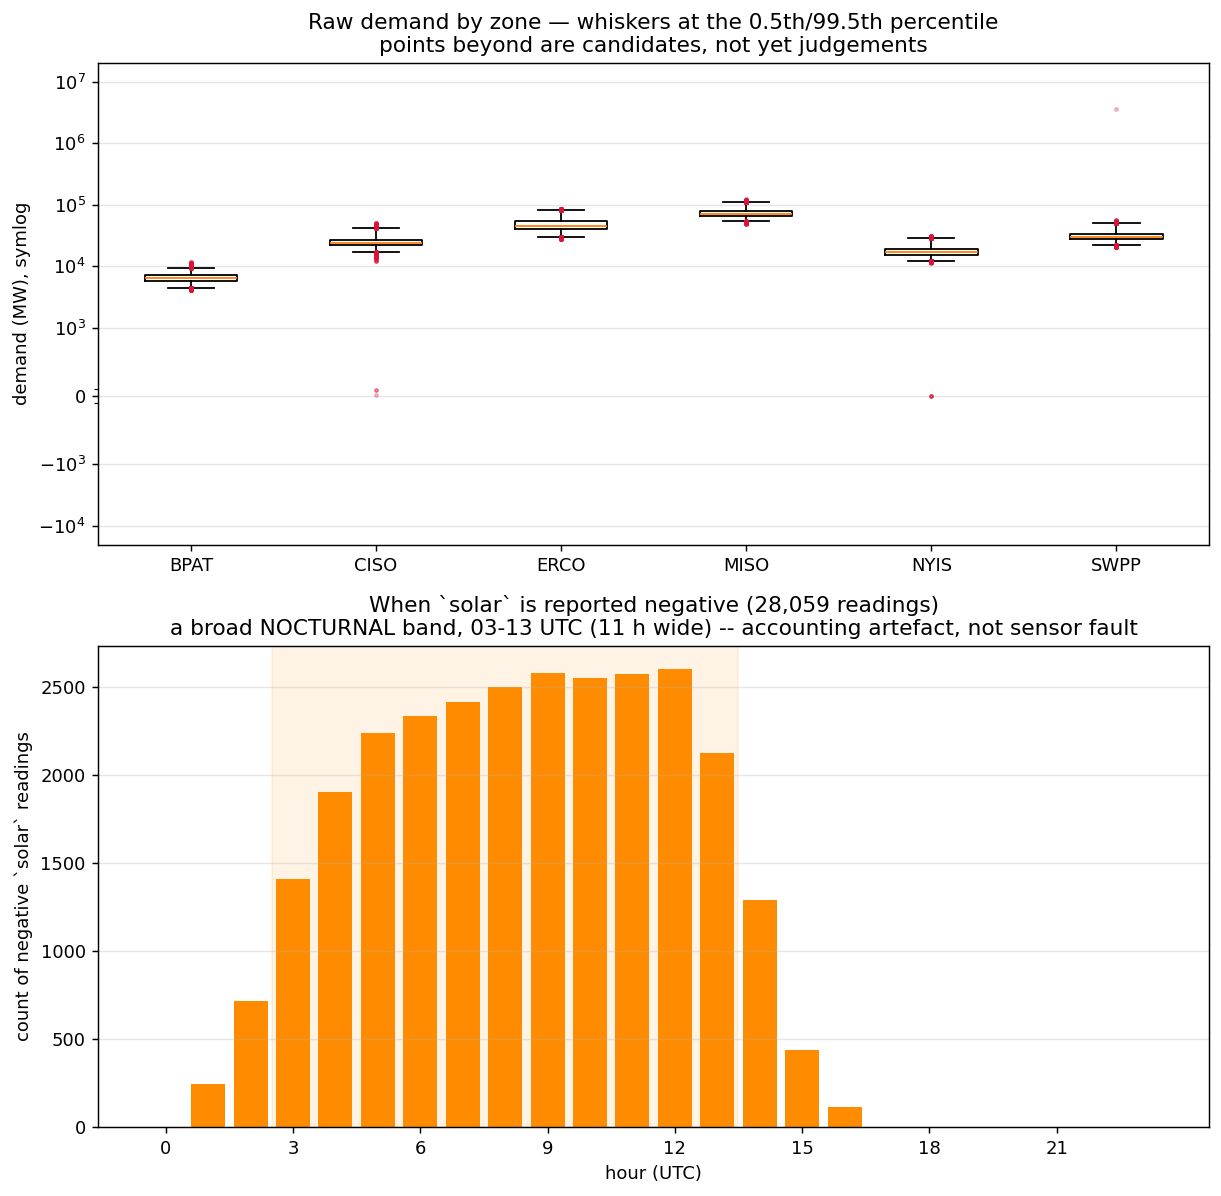

negative-solar CORE band (middle 90%): 03:00-13:00 UTC, 11 hours wide; full extent 01:00-22:00 UTC; peak 2,606 readings at 12:00 UTC
--- negative values by column (raw) ---
total_interchange    201687
dew_point             65379
apparent_temp         50656
solar                 28059
temp                  26342
other                 23200
coal                   3546
nuclear                1443
unknown_storage        1337
oil                     986
wind                    452
solar_battery           196
hydro                   141

--- magnitudes that cannot be real ---
Screen: above 150,000 MW, beyond the largest genuine hour in the panel (MISO, 121,560 MW; see 0.5).

demand: 1 row(s) above 150,000 MW
          timestamp zone    demand      wind  solar  net_generation
2023-06-13 02:00:00 SWPP 3621097.0 3589445.0   32.0       3617992.0

wind: 1 row(s) above 150,000 MW
          timestamp zone    demand      wind  solar  net_generation
2023-06-13 02:00:00 SWPP 3621097.0 3589445.0   32.0


NYIS: median demand 16,830 MW; 4 hour(s) below 10% of it
          timestamp  demand  wind  solar
2019-04-18 04:00:00     0.0   NaN    NaN
2024-01-18 00:00:00     0.0   NaN    NaN
2024-10-09 21:00:00     0.0   0.0    0.0
2024-10-09 22:00:00     0.0 628.0    0.0


In [4]:
# WHAT: (a) raw demand per zone on a symlog axis; (b) when negative solar happens.
# WHY:  symlog because the raw range spans 0 to 3.6 million MW -- a linear axis would show
#       one spike and six flat lines, and a log axis cannot render the zeros.
fig, axes = plt.subplots(2, 1, figsize=(9.5, 9.3))

data = [raw.loc[raw[cfg.GROUP_COL] == z, "demand"].dropna().to_numpy() for z in zones]
bp = axes[0].boxplot(data, showfliers=True, whis=(0.5, 99.5),
                     flierprops=dict(marker=".", ms=3, alpha=.4, mec="crimson"))
# boxplot's `labels=` was renamed `tick_labels=` in matplotlib 3.9 and removed in 3.11;
# setting the ticks explicitly works on every version this project supports (>=3.8).
axes[0].set_xticks(range(1, len(zones) + 1), zones)
axes[0].set_yscale("symlog", linthresh=1000)
# Explicit major ticks: symlog's automatic ticks piled 10^2, 10^1 and -10^2 into
# an unreadable smudge at zero, and the SWPP point at 3.6 million sat on the edge.
axes[0].set_yticks([-1e4, -1e3, 0, 1e3, 1e4, 1e5, 1e6, 1e7])
axes[0].yaxis.set_minor_formatter(plt.NullFormatter())
axes[0].set_ylim(-2e4, 2e7)
axes[0].set_ylabel("demand (MW), symlog")
axes[0].set_title("Raw demand by zone — whiskers at the 0.5th/99.5th percentile\n"
                  "points beyond are candidates, not yet judgements")
axes[0].grid(axis="y", alpha=.3)

# negative solar by UTC hour, pooled across the zones that report solar
neg = raw[raw["solar"] < 0].copy()
if len(neg):
    neg["utc_hour"] = neg[cfg.TIME_COL].dt.hour
    cnt = neg.groupby("utc_hour").size().reindex(range(24), fill_value=0)
    axes[1].bar(cnt.index, cnt.values, color="darkorange")
    axes[1].set_xlabel("hour (UTC)")
    axes[1].set_ylabel("count of negative `solar` readings")
    # DESCRIBE THE BAND FROM THE DATA. The old subtitle said "dawn/dusk
    # concentration", which would be two narrow spikes. What is actually there is a
    # broad nocturnal band -- measured below as the contiguous span of hours holding
    # the middle 90% of the readings. The conclusion (an accounting artefact, not a
    # sensor fault) survives the correction; the description did not.
    # The CORE band, not the full extent. Taking the first and last non-zero hour
    # would report 22 hours because a handful of readings sit in the tails; the
    # honest summary of "when does this happen" is the contiguous span holding the
    # middle 90% of the readings. Both are printed below.
    _cum = cnt.cumsum() / cnt.sum()
    lo_h = int(_cum[_cum >= 0.05].index.min()); hi_h = int(_cum[_cum <= 0.95].index.max())
    band_w = hi_h - lo_h + 1
    full_lo = int(cnt[cnt > 0].index.min()); full_hi = int(cnt[cnt > 0].index.max())
    axes[1].axvspan(lo_h - 0.5, hi_h + 0.5, color="darkorange", alpha=0.10, zorder=0)
    axes[1].set_title(f"When `solar` is reported negative ({len(neg):,} readings)\n"
                      f"a broad NOCTURNAL band, {lo_h:02d}-{hi_h:02d} UTC "
                      f"({band_w} h wide) -- accounting artefact, not sensor fault")
    axes[1].set_xticks(range(0, 24, 3))
    axes[1].grid(axis="y", alpha=.3)
plt.tight_layout()
plt.savefig(cfg.FIGURES / "01_impossible_values.png", bbox_inches="tight")
plt.show()

print(f"negative-solar CORE band (middle 90%): {lo_h:02d}:00-{hi_h:02d}:00 UTC, "
      f"{band_w} hours wide; full extent {full_lo:02d}:00-{full_hi:02d}:00 UTC; "
      f"peak {int(cnt.max()):,} readings at {int(cnt.idxmax()):02d}:00 UTC")

print("--- negative values by column (raw) ---")
negs = {c: int((raw[c] < 0).sum()) for c in measure_cols
        if pd.api.types.is_numeric_dtype(raw[c]) and (raw[c] < 0).any()}
print(pd.Series(negs).sort_values(ascending=False).to_string())

print("\n--- magnitudes that cannot be real ---")
print("Screen: above 150,000 MW, beyond the largest genuine hour in the panel (MISO, 121,560 MW; see 0.5).")
for c in ("demand", "wind", "net_generation"):
    bad = raw[raw[c] > 150_000]
    if len(bad):
        print(f"\n{c}: {len(bad)} row(s) above 150,000 MW")
        print(bad[[cfg.TIME_COL, cfg.GROUP_COL, "demand", "wind", "solar",
                   "net_generation"]].to_string(index=False))

print("\n--- demand far BELOW a plausible floor (a BA always serves load) ---")
for z in zones:
    g = raw[raw[cfg.GROUP_COL] == z]
    med = g["demand"].median()
    low = g[g["demand"] < 0.10 * med]
    if len(low):
        print(f"\n{z}: median demand {med:,.0f} MW; {len(low)} hour(s) below 10% of it")
        print(low[[cfg.TIME_COL, "demand", "wind", "solar"]].to_string(index=False))

**Figure: `01_impossible_values.png` — magnitudes that cannot be real, and when `solar` is reported negative.**

**What I see:** Five zones sit between roughly 6,000 MW (BPAT) and 70,000 MW (MISO). One SWPP row
(`2023-06-13 02:00`) has `demand` 3,621,097, `wind` 3,589,445 and `net_generation` 3,617,992. CISO has hours
at 14, 91 and 96 MW against a median of 24,086 MW, and NYIS has four hours at 0.0. The 28,059 negative
`solar` readings span 01:00–22:00 UTC, but the middle 90% fall in an 11-hour band, 03:00–13:00 UTC, peaking
at 2,606 readings at 12:00 UTC.

**What it means:** The SWPP row is one corrupt record. The CISO and NYIS floors are reporting failures, since
a balancing authority always serves load. Negative solar is not an error: it is a nocturnal band (all from
CISO and BPAT, so 12:00 UTC is before local sunrise), i.e. auxiliary draw netted against zero output.

**What I do:** Null the impossible values (8 `demand`, 2 `other`, 1 `wind`, 1 `net_generation`; the eight
`demand` nulls are the SWPP row plus CISO's three and NYIS's four). Clip negative `solar`, `wind`, `hydro`
and `nuclear` to zero. Negative `coal`, `oil` and `other` are left as reported. The clip count for solar is
28,066, seven more than the figure, because interpolating short gaps creates a few small negatives.

### 0.5 — Apply the contract, derive the target, write `panel.parquet`

Run the rules, derive `net_load`, `renewable_share` and `ramp`, and write the cleaned panel. Plausibility
bounds run before interpolation, so a corrupt value is never spread to its neighbours. `ramp(t) =
net_load(t) − net_load(t−1)` is looked up by timestamp, not `shift(1)`, because dropped rows leave holes.
`ramp` contains `net_load(t)`, so it is descriptive only and `MutualInfoSelector.DROP_ALWAYS` keeps it out of
the features. Every change in the before/after table should trace back to 0.2–0.4.

In [5]:
# WHAT: apply the contract, derive the target, write panel.parquet.
# WHY:  the logic lives in src/ because it is tested and reused; this notebook supplies
#       the evidence and the argument for each rule.
from src.data import build_clean_panel

df, report = build_clean_panel(raw, verbose=True)

print("\n================ the contract, as applied ================")
print(f"rows in  (raw)      : {len(raw):,}")
print(f"rows out (cleaned)  : {len(df):,}")
print(f"rows lost           : {len(raw) - len(df):,} "
      f"({100 * (len(raw) - len(df)) / len(raw):.3f}%)")
print(f"\nduplicate (zone, hour) rows dropped : {report['duplicate_rows_dropped']:,}")
print(f"implausible values set to NaN       : {report.get('implausible_values_nulled', {})}")
print(f"negative generation clipped to 0    : {report.get('negative_generation_clipped', {})}")
print(f"interpolation cap                   : {report['interp_limit_hours']} hours")
print(f"rows dropped, target unrecoverable  : {report['rows_dropped_missing_target']:,}")

gap_tbl = pd.DataFrame({
    "missing_before_interp": pd.Series(report.get("missing_before_interp", {})),
    "missing_after_interp": pd.Series(report.get("missing_after_interp", {})),
}).fillna(0).astype(int)
gap_tbl["recovered_by_interp"] = (gap_tbl["missing_before_interp"]
                                  - gap_tbl["missing_after_interp"])
print("\n--- gaps before and after the 3-hour cap ---")
display(gap_tbl.sort_values("missing_before_interp", ascending=False))

# The audit that matters: what did the contract change about the numbers?
compare = []
for c in ("demand", "wind", "solar", "net_generation"):
    compare.append({"column": c,
                    "raw_min": raw[c].min(), "raw_max": raw[c].max(),
                    "clean_min": df[c].min(), "clean_max": df[c].max()})
print("\n--- before / after, the columns the bounds touched ---")
display(pd.DataFrame(compare).set_index("column").round(1))

print("\n--- the derived columns (these did not exist in the raw panel) ---")
display(df[[cfg.TARGET, "renewable_share", "ramp"]].describe().round(2))

# The identity, checked with the SAME fillna(0) the loader uses. Without the fillna a
# NaN makes the residual NaN, and Series.max() SKIPS NaN -- so the check would pass on
# whatever subset happened to be complete.
resid = (df[cfg.TARGET]
         - (df["demand"] - df["wind"].fillna(0) - df["solar"].fillna(0))).abs()
print(f"\nmax identity residual: {resid.max():.3e} over {resid.notna().sum():,} rows")
assert resid.max() < 1e-6, "net_load identity violated"
assert df[cfg.TARGET].isna().sum() == 0, "target still has missing values"
print(f"panel.parquet written: {len(df):,} rows x {df.shape[1]} columns")

R.save("nb01", dict(
    rows_clean=int(len(df)),
    rows_raw=int(len(raw)),
    rows_dropped=int(len(raw) - len(df)),
    duplicate_rows_dropped=int(report["duplicate_rows_dropped"]),
    implausible_values_nulled={k: int(v) for k, v in
                               report.get("implausible_values_nulled", {}).items()},
    negative_generation_clipped={k: int(v) for k, v in
                                 report.get("negative_generation_clipped", {}).items()},
    interp_limit_hours=int(report["interp_limit_hours"]),
    max_identity_residual=float(resid.max()),
));


panel.parquet written: 315,485 rows x 35 columns
  dropped from raw: 163 rows
  gaps left after 3h interpolation: {'demand': 96, 'demand_forecast': 265, 'net_generation': 120, 'total_interchange': 551, 'coal': 52717, 'gas': 172, 'nuclear': 149, 'oil': 157870, 'other': 8018, 'solar': 172, 'hydro': 8029, 'wind': 153, 'battery': 314311, 'unknown_storage': 314311, 'solar_battery': 314241}

================ the contract, as applied ================
rows in  (raw)      : 315,648
rows out (cleaned)  : 315,485
rows lost           : 163 (0.052%)

duplicate (zone, hour) rows dropped : 0
implausible values set to NaN       : {'demand': 8, 'other': 2, 'net_generation': 1, 'wind': 1}
negative generation clipped to 0    : {'solar': 28066, 'wind': 452, 'hydro': 142, 'nuclear': 1443}
interpolation cap                   : 3 hours
rows dropped, target unrecoverable  : 163

--- gaps before and after the 3-hour cap ---


,missing_before_interp,missing_after_interp,recovered_by_interp
battery,314311,314311,0
unknown_storage,314311,314311,0
solar_battery,314241,314241,0
oil,157908,157870,38
coal,52761,52717,44
hydro,8073,8029,44
other,8061,8018,43
total_interchange,574,551,23
demand_forecast,265,265,0
solar,228,172,56



--- before / after, the columns the bounds touched ---


,raw_min,raw_max,clean_min,clean_max
column,,,,
demand,0.0,3621097.0,4038.0,121560.0
wind,-2323.0,3589445.0,0.0,27667.0
solar,-431.0,21589.0,0.0,21589.0
net_generation,0.0,3617992.0,207.0,118316.0



--- the derived columns (these did not exist in the raw panel) ---


,net_load,renewable_share,ramp
count,315485.00,315485.00,315468.00
mean,26531.18,0.20,0.05
std,20198.33,0.18,1697.12
min,-627.00,0.00,-18767.00
25%,13084.00,0.05,-714.00
50%,19880.00,0.15,-28.00
75%,34790.00,0.31,638.00
max,113175.00,1.05,14432.00



max identity residual: 0.000e+00 over 315,485 rows
panel.parquet written: 315,485 rows x 35 columns
[results read-only] nb01: 8 key(s) verified against the ledger, nothing written


## Pass 1 — Structure

### 1.2 — Shape, dtypes, granularity

Check that the cleaned series is hourly with no duplicates. Almost every step is 1 hour; the longer steps
are the holes left by the rows dropped in 0.5, including the 25-hour steps around the 24-hour outages.
There are no duplicate (zone, timestamp) pairs, so there are no DST artefacts.

In [6]:
g = df.sort_values(cfg.TIME_COL).groupby(cfg.GROUP_COL)[cfg.TIME_COL]
gaps = g.diff().dt.total_seconds().div(3600).value_counts().head()
print(gaps)
print('duplicate (zone, timestamp):', df.duplicated([cfg.GROUP_COL, cfg.TIME_COL]).sum())

timestamp
1.0     315468
25.0         5
6.0          2
12.0         1
5.0          1
Name: count, dtype: int64


duplicate (zone, timestamp): 0


## Pass 2 — Quality

### 1.3 — Outliers by two methods

IQR flags (1.5× IQR) and MAD flags (modified z-score above 3.5), per zone and variable. They disagree on
heavy-tailed data, so reporting both forces an explicit keep / cap / drop decision. A flagged value is not
automatically an error.

--- IQR vs MAD flag rates, per zone and per variable ---
       variable zone     n  iqr_pct  mad_pct  both_n       min       max  skew  kurt
       net_load BPAT 52538     0.43     0.04      23   1719.00  10987.00  0.22 -0.18
       net_load CISO 52580     1.53     0.17      91   -627.00  47464.00  0.10  0.22
       net_load ERCO 52608     0.40     0.00       0  10551.00  70443.00  0.51 -0.28
       net_load MISO 52584     1.77     0.21     110  33727.00 113175.00  0.67  0.21
       net_load NYIS 52591     3.19     1.26     665  10479.00  30687.00  0.96  1.14
       net_load SWPP 52584     0.72     0.01       7   3075.00  50238.00  0.59 -0.13
           ramp BPAT 52532     1.46     0.22     116  -2539.00   5231.00  0.32  3.57
           ramp CISO 52577     7.93     5.15    2708 -12744.00  14430.00  0.84  2.53
           ramp ERCO 52607     2.24     0.48     255 -11830.00  14432.00  0.05  0.91
           ramp MISO 52582     1.32     0.03      14  -8112.00   8047.00 -0.03  0.11
        

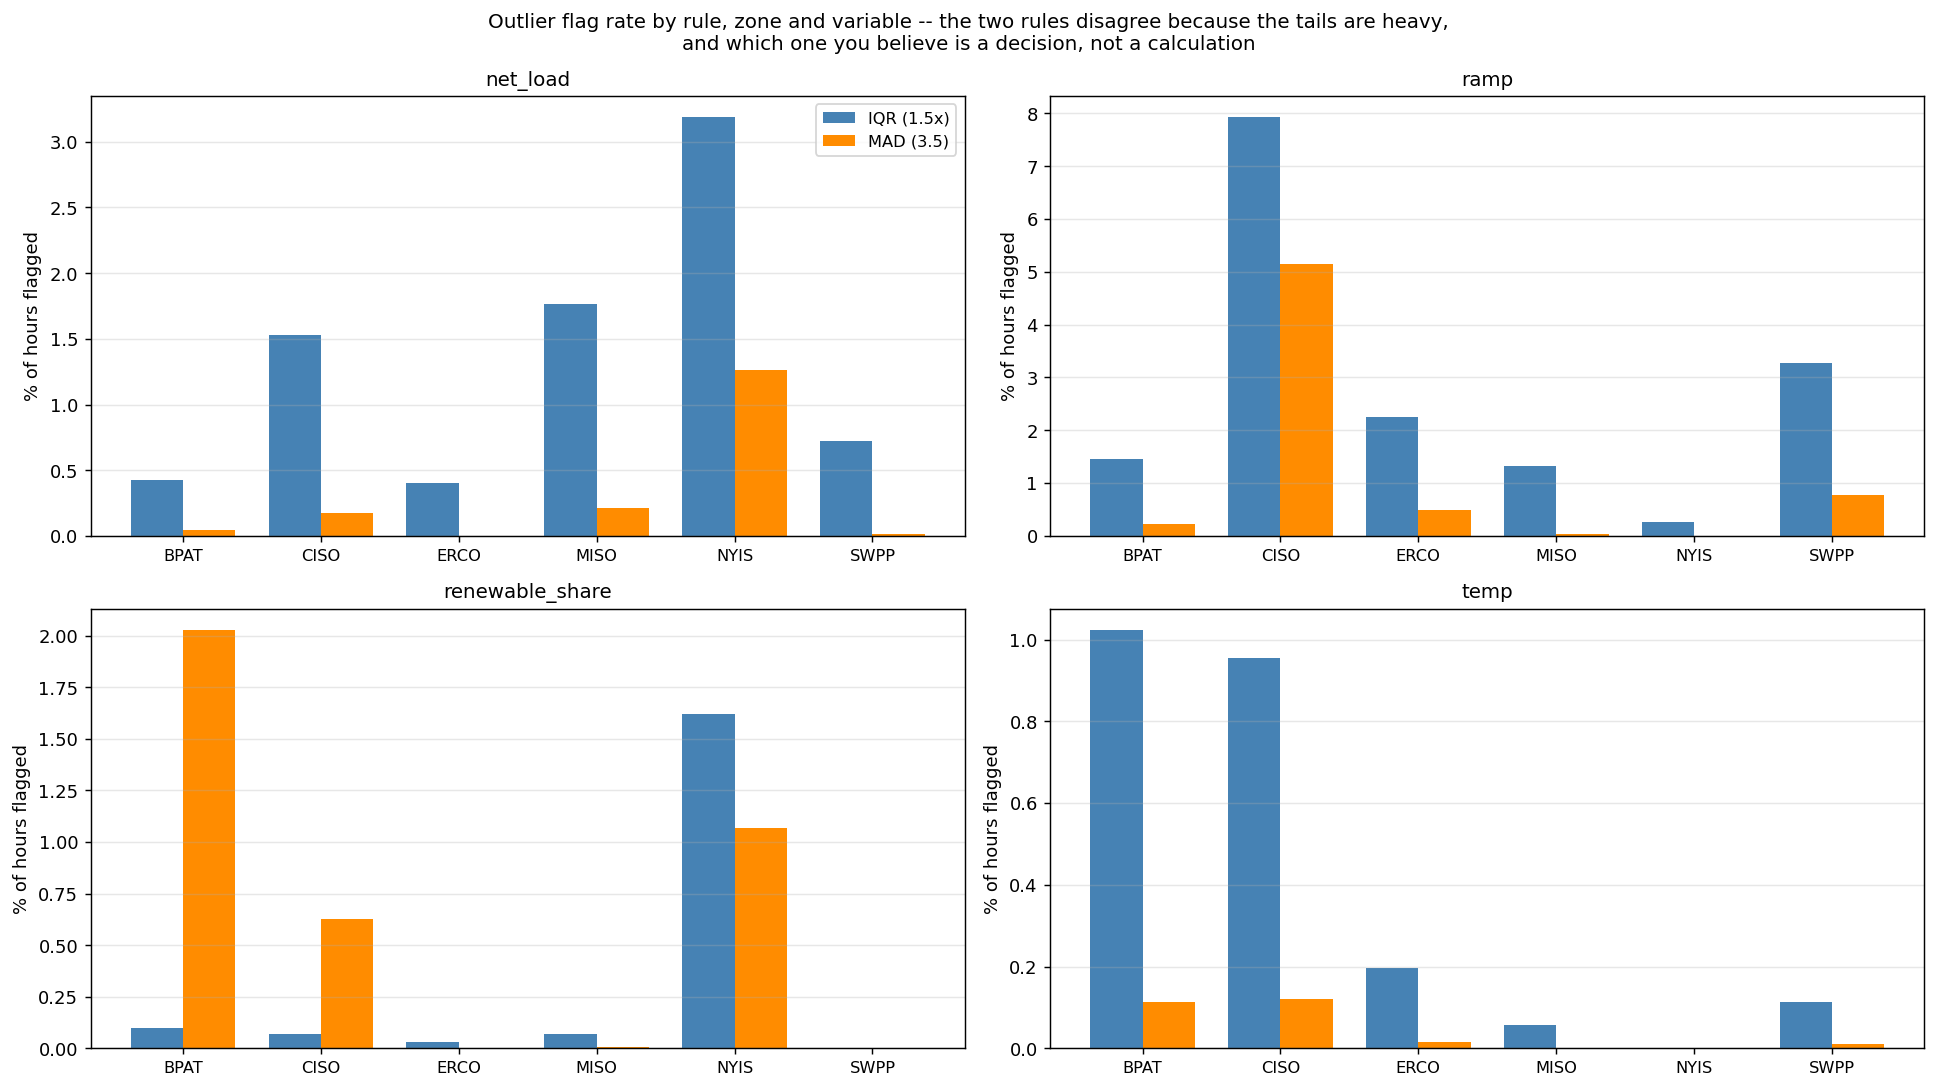


--- the eight largest |ramp| hours in the panel ---
          timestamp zone  net_load     ramp  demand    wind  solar  temp
2024-07-20 06:00:00 SWPP   17914.0 -18767.0 32377.0 14463.0    0.0  23.7
2019-06-21 06:00:00 SWPP   17166.0 -18331.0 31379.0 14213.0    0.0  27.2
2019-09-24 06:00:00 SWPP   15539.0 -18239.0 27452.0 11913.0    0.0  23.9
2024-02-15 07:00:00 SWPP   11094.0 -17746.0 27958.0 16864.0    0.0  10.9
2024-02-03 07:00:00 SWPP    7710.0 -16213.0 26878.0 19168.0    0.0  13.2
2021-08-20 06:00:00 SWPP   16108.0 -14607.0 32910.0 16802.0    0.0  25.3
2024-01-10 00:00:00 ERCO   43750.0  14432.0 50828.0  5371.0 1707.0   6.4
2019-02-20 01:00:00 CISO   19546.0  14430.0 22134.0  1317.0 1271.0  11.3

--- every hour where net load went NEGATIVE ---
          timestamp zone  net_load  demand   wind  solar  renewable_share
2019-04-10 23:00:00 CISO    -627.0 12193.0 3398.0 9422.0         1.051423

renewable_share = (wind + solar) / demand, so a value above 1.0 and a negative net load are


In [7]:
# WHAT: IQR and MAD outlier flags, per zone AND per variable, with an explicit
#       keep / cap / drop decision written against each group.
# WHY:  the two rules disagree on heavy-tailed data by construction. IQR is built on
#       quartiles (it breaks down once >25% of the data is extreme); MAD is built on the
#       median absolute deviation (breakdown 50%), so it is the stricter of the two here.
#       Reporting both forces the decision to be explicit rather than implicit.
#
# WHAT THIS PASS IS *NOT*: section 0.4 already removed the physically IMPOSSIBLE values.
# Everything flagged below is extreme-but-possible, which is a different question with a
# different answer -- and on this dataset the extremes are the subject, not the noise.

def iqr_flags(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)


def mad_flags(s, thresh=3.5):
    med = s.median(); mad = (s - med).abs().median()
    return (0.6745 * (s - med) / (mad if mad else np.nan)).abs() > thresh


OUTLIER_VARS = [cfg.TARGET, "ramp", "renewable_share", "temp"]

rows = []
for v in OUTLIER_VARS:
    for z in zones:
        s = df.loc[df[cfg.GROUP_COL] == z, v].dropna()
        if not len(s):
            continue
        i, m = iqr_flags(s), mad_flags(s)
        rows.append({"variable": v, "zone": z, "n": len(s),
                     "iqr_pct": 100 * i.mean(), "mad_pct": 100 * m.mean(),
                     "both_n": int((i & m).sum()),
                     "min": s.min(), "max": s.max(),
                     "skew": s.skew(), "kurt": s.kurt()})
outl = pd.DataFrame(rows)

print("--- IQR vs MAD flag rates, per zone and per variable ---")
print(outl.round(2).to_string(index=False))

fig, axes = plt.subplots(2, 2, figsize=(15, 8.5))
x = np.arange(len(zones)); w = 0.38
for ax, v in zip(axes.ravel(), OUTLIER_VARS):
    sub_ = outl[outl["variable"] == v].set_index("zone").reindex(zones)
    ax.bar(x - w / 2, sub_["iqr_pct"], w, label="IQR (1.5x)", color="steelblue")
    ax.bar(x + w / 2, sub_["mad_pct"], w, label="MAD (3.5)", color="darkorange")
    ax.set_xticks(x); ax.set_xticklabels(zones, fontsize=9)
    ax.set_title(v, fontsize=11)
    ax.set_ylabel("% of hours flagged")
    ax.grid(axis="y", alpha=.3)
axes[0, 0].legend(fontsize=9)
fig.suptitle("Outlier flag rate by rule, zone and variable -- the two rules disagree "
             "because the tails are heavy,\nand which one you believe is a decision, "
             "not a calculation", fontsize=11)
plt.tight_layout()
plt.savefig(cfg.FIGURES / "01_outliers.png", bbox_inches="tight")
plt.show()

# The evidence the decision rests on: are the biggest flagged values defects or events?
print("\n--- the eight largest |ramp| hours in the panel ---")
ext = df.reindex(df["ramp"].abs().sort_values(ascending=False).index).head(8)
print(ext[[cfg.TIME_COL, cfg.GROUP_COL, cfg.TARGET, "ramp",
           "demand", "wind", "solar", "temp"]].to_string(index=False))

print("\n--- every hour where net load went NEGATIVE ---")
negrows = df[df[cfg.TARGET] < 0]
print(negrows[[cfg.TIME_COL, cfg.GROUP_COL, cfg.TARGET, "demand", "wind",
               "solar", "renewable_share"]].to_string(index=False))
print(f"\nrenewable_share = (wind + solar) / demand, so a value above 1.0 and a negative "
      f"net load are\nthe SAME event. Panel max renewable_share: "
      f"{df['renewable_share'].max():.3f}")

# DECISION: keep everything. Recorded so the choice is auditable, not implied.
decision = {v: "keep" for v in OUTLIER_VARS}
R.save("nb01", dict(
    outlier_rule_flag_rates={
        f"{r.variable}|{r.zone}": {"iqr_pct": round(float(r.iqr_pct), 3),
                                   "mad_pct": round(float(r.mad_pct), 3)}
        for r in outl.itertuples()},
    outlier_shape={f"{r.variable}|{r.zone}": {"skew": round(float(r.skew), 3),
                                              "kurt": round(float(r.kurt), 3)}
                   for r in outl.itertuples()},
    outlier_extreme_ramp_rows=[{"zone": z, "wind_mw": float(w), "ramp_mw": float(rp)}
                               for z, w, rp in zip(ext[cfg.GROUP_COL], ext["wind"], ext["ramp"])],
    outlier_decision=decision,
    outlier_max_abs_ramp_mw=float(df["ramp"].abs().max()),
    negative_net_load_hours=int((df[cfg.TARGET] < 0).sum()),
    max_renewable_share=float(df["renewable_share"].max()),
))
print(f"\nDECISION -> {decision}  (argued in the cell below)")


**What I see:** The two rules disagree almost everywhere, and MAD is usually stricter. On `net_load` the gap
is widest at NYIS (IQR 3.19% vs MAD 1.26%). On `ramp` CISO stands out (7.93% IQR, 5.15% MAD). `temp` is
almost never flagged. `renewable_share` inverts the pattern at BPAT (MAD 2.03%, IQR 0.10%). Ramps are heavy
tailed (kurtosis 4.46 at SWPP, 3.57 at BPAT). Six of the eight largest ramps are SWPP at 06:00–07:00 UTC,
with wind at 11,913–19,168 MW and zero solar. Net load went negative in exactly one hour of 315,485 (CISO,
2019, 23:00 UTC), the same hour as the maximum `renewable_share` of 1.051.

**What it means:** Nothing here is a defect. The biggest ramps are overnight SWPP wind surges, which is the
kind of event the project forecasts. CISO's high ramp rate fits a solar-heavy system ramping twice a day
(argued, not shown here). BPAT's `renewable_share` disagreement comes from a tightly clustered distribution
with a tiny MAD. The negative net-load hour is wind plus solar briefly exceeding CISO demand.

**What I do:** Keep every flagged value in all four variables; 0.4 already removed the impossible ones. Two
consequences: the heavy ramp tails argue for MAE over RMSE in notebook 04, and since the target can be
negative, log or multiplicative transforms are ruled out.

## Pass 3 — Univariate

### 1.4 — Distributions with bootstrap CIs

An 80-bin histogram of pooled `net_load`, with skew, kurtosis and a bootstrap CI for `net_load`,
`renewable_share` and `ramp`. The shape informs the metric choice in notebook 04.

net_load         mean=   26531.2  95% CI of a 20k-row subsample mean=(26122.4, 26668.5)  skew=  1.25  kurt=  0.93


renewable_share  mean=       0.2  95% CI of a 20k-row subsample mean=(0.2, 0.2)  skew=  0.95  kurt=  0.07


ramp             mean=       0.1  95% CI of a 20k-row subsample mean=(-31.6, 15.7)  skew=  0.21  kurt=  3.50


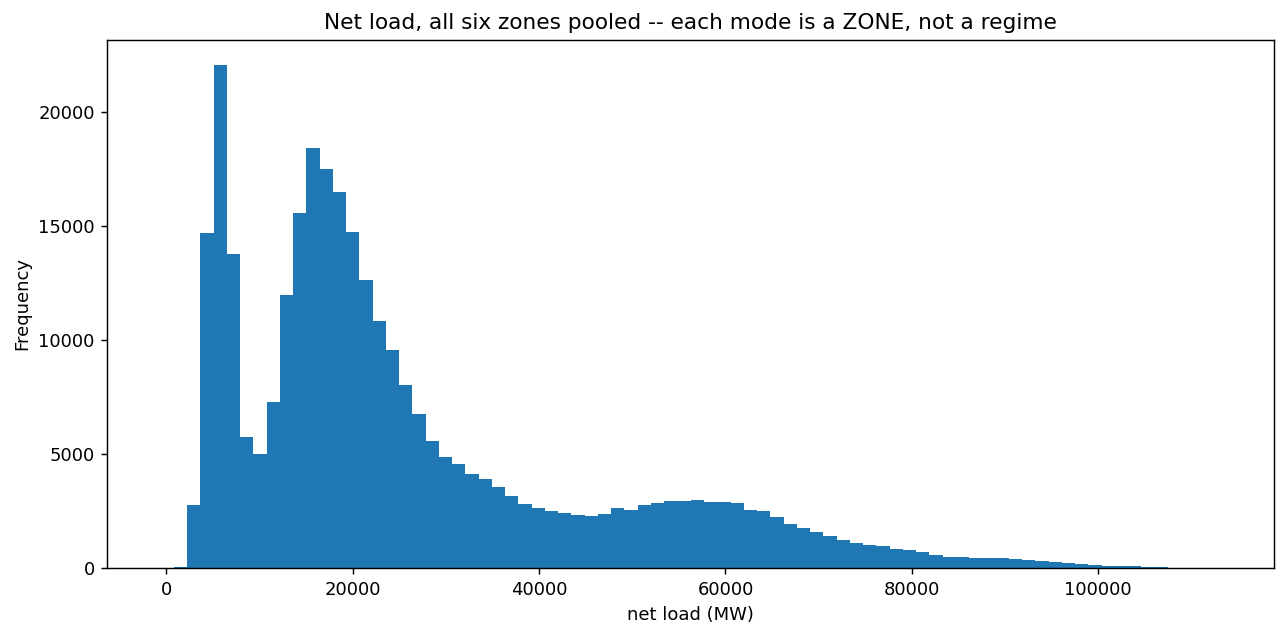

In [8]:
def bootstrap_ci(x, stat=np.mean, n=2000, alpha=0.05, seed=cfg.SEED):
    rng = np.random.default_rng(seed); x = np.asarray(x)
    b = [stat(rng.choice(x, len(x), replace=True)) for _ in range(n)]
    return float(np.percentile(b, 100*alpha/2)), float(np.percentile(b, 100*(1-alpha/2)))

for v in [cfg.TARGET, 'renewable_share', 'ramp']:
    s = df[v].dropna()
    lo, hi = bootstrap_ci(s.sample(min(20000, len(s)), random_state=cfg.SEED))
    print(f'{v:16s} mean={s.mean():10.1f}  95% CI of a 20k-row subsample mean=({lo:.1f}, {hi:.1f})  skew={s.skew():6.2f}  kurt={s.kurt():6.2f}')

ax = df[cfg.TARGET].plot.hist(
    bins=80,
    title='Net load, all six zones pooled -- each mode is a ZONE, not a regime')
ax.set_xlabel('net load (MW)')
plt.tight_layout(); plt.savefig(cfg.FIGURES / '01_target_hist.png'); plt.show()

**Figure: `01_target_hist.png` — the distribution of `net_load`, pooled over all six zones.**

**What I see:** `net_load` mean 26,531.2 MW, skew 1.25, kurtosis 0.93; `ramp` kurtosis 3.50. The histogram
is strongly multimodal: a narrow spike near 5,500 MW, a broad mode around 14,000–20,000 MW, a shoulder near
55,000–60,000 MW, and a tail to 113,175 MW. Each mode matches a zone's range (BPAT 1,719 to 10,987 MW, MISO
33,727 to 113,175).

**What it means:** This is a mixture of zones, not one distribution, so the pooled skew mostly reflects MISO
being much larger than BPAT. The one statistic about behaviour is `ramp`'s kurtosis of 3.50: hour-to-hour
changes have heavy tails. The printed CI is computed on a 20,000-row subsample (centred at 26,395.5,
half-width 273.1 MW), not on the full series behind the printed mean.

**What I do:** Report moments per zone, not pooled. Do not quote this CI for the full-sample mean; at
n = 315,485 the CLT interval is about ±70 MW.

## Pass 4 — Bivariate and multivariate

### 1.5 — Pearson and Spearman side by side, pooled and within each region

Every pair of numeric columns under Pearson and Spearman (`01_corr.png`), then every column against
`net_load`, pooled and within each region (`01_corr_target.png`). Pearson measures fit to a straight line
and is sensitive to extremes; Spearman is Pearson on ranks and captures any monotone relationship. Neither
sees a U-shape. Because the six grids differ in size by about ten times, a pooled correlation mixes
within-grid behaviour with which grid a row comes from; the within-region value (median of the six) removes
that.

In `01_corr.png` the upper triangle is Pearson and the lower is Spearman. In `01_corr_target.png` (a),
`*` marks the target's own ingredients and a red name marks a sign flip between pooled and within-region.

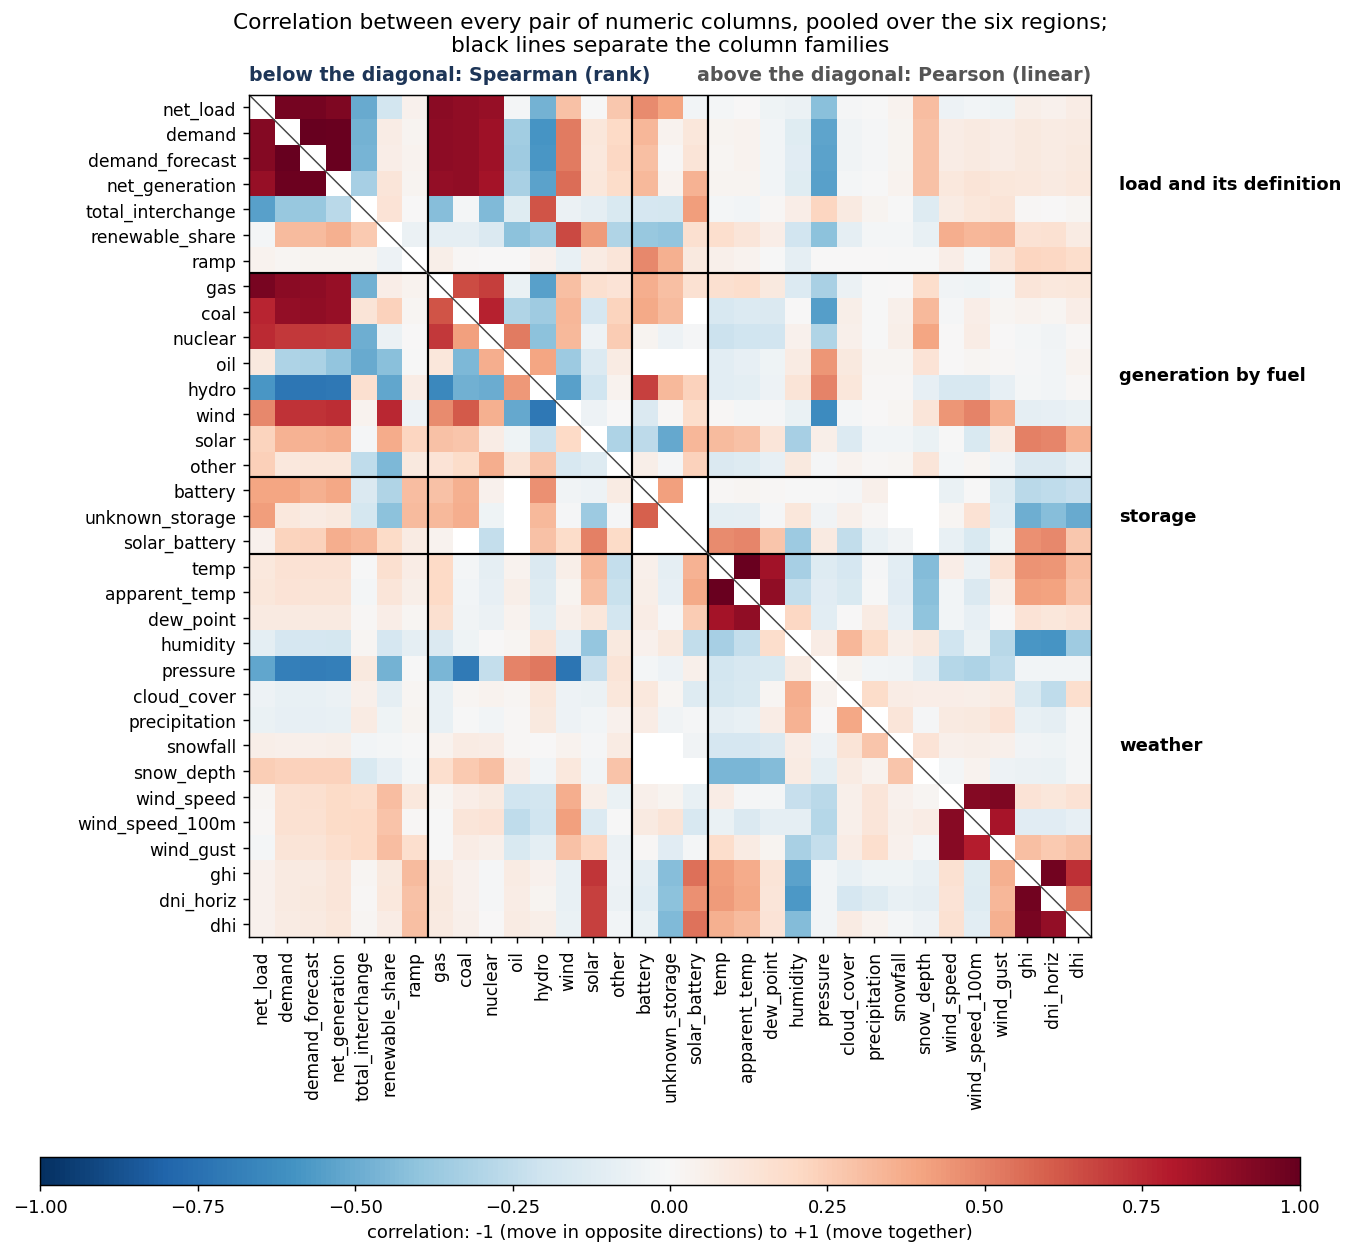

--- association with the target, every numeric column ---
                   pearson_abs  spearman_abs
gas                      0.901         0.945
demand                   0.959         0.920
demand_forecast          0.959         0.919
net_generation           0.932         0.874
coal                     0.883         0.758
nuclear                  0.874         0.749
hydro                    0.472         0.583
total_interchange        0.504         0.545
pressure                 0.417         0.518
wind                     0.292         0.483
unknown_storage          0.393         0.422
battery                  0.476         0.397
snow_depth               0.309         0.248
other                    0.272         0.236
solar                    0.003         0.220
apparent_temp            0.003         0.112
temp                     0.020         0.102
oil                      0.020         0.100
humidity                 0.062         0.096
dew_point                0.046         0.0

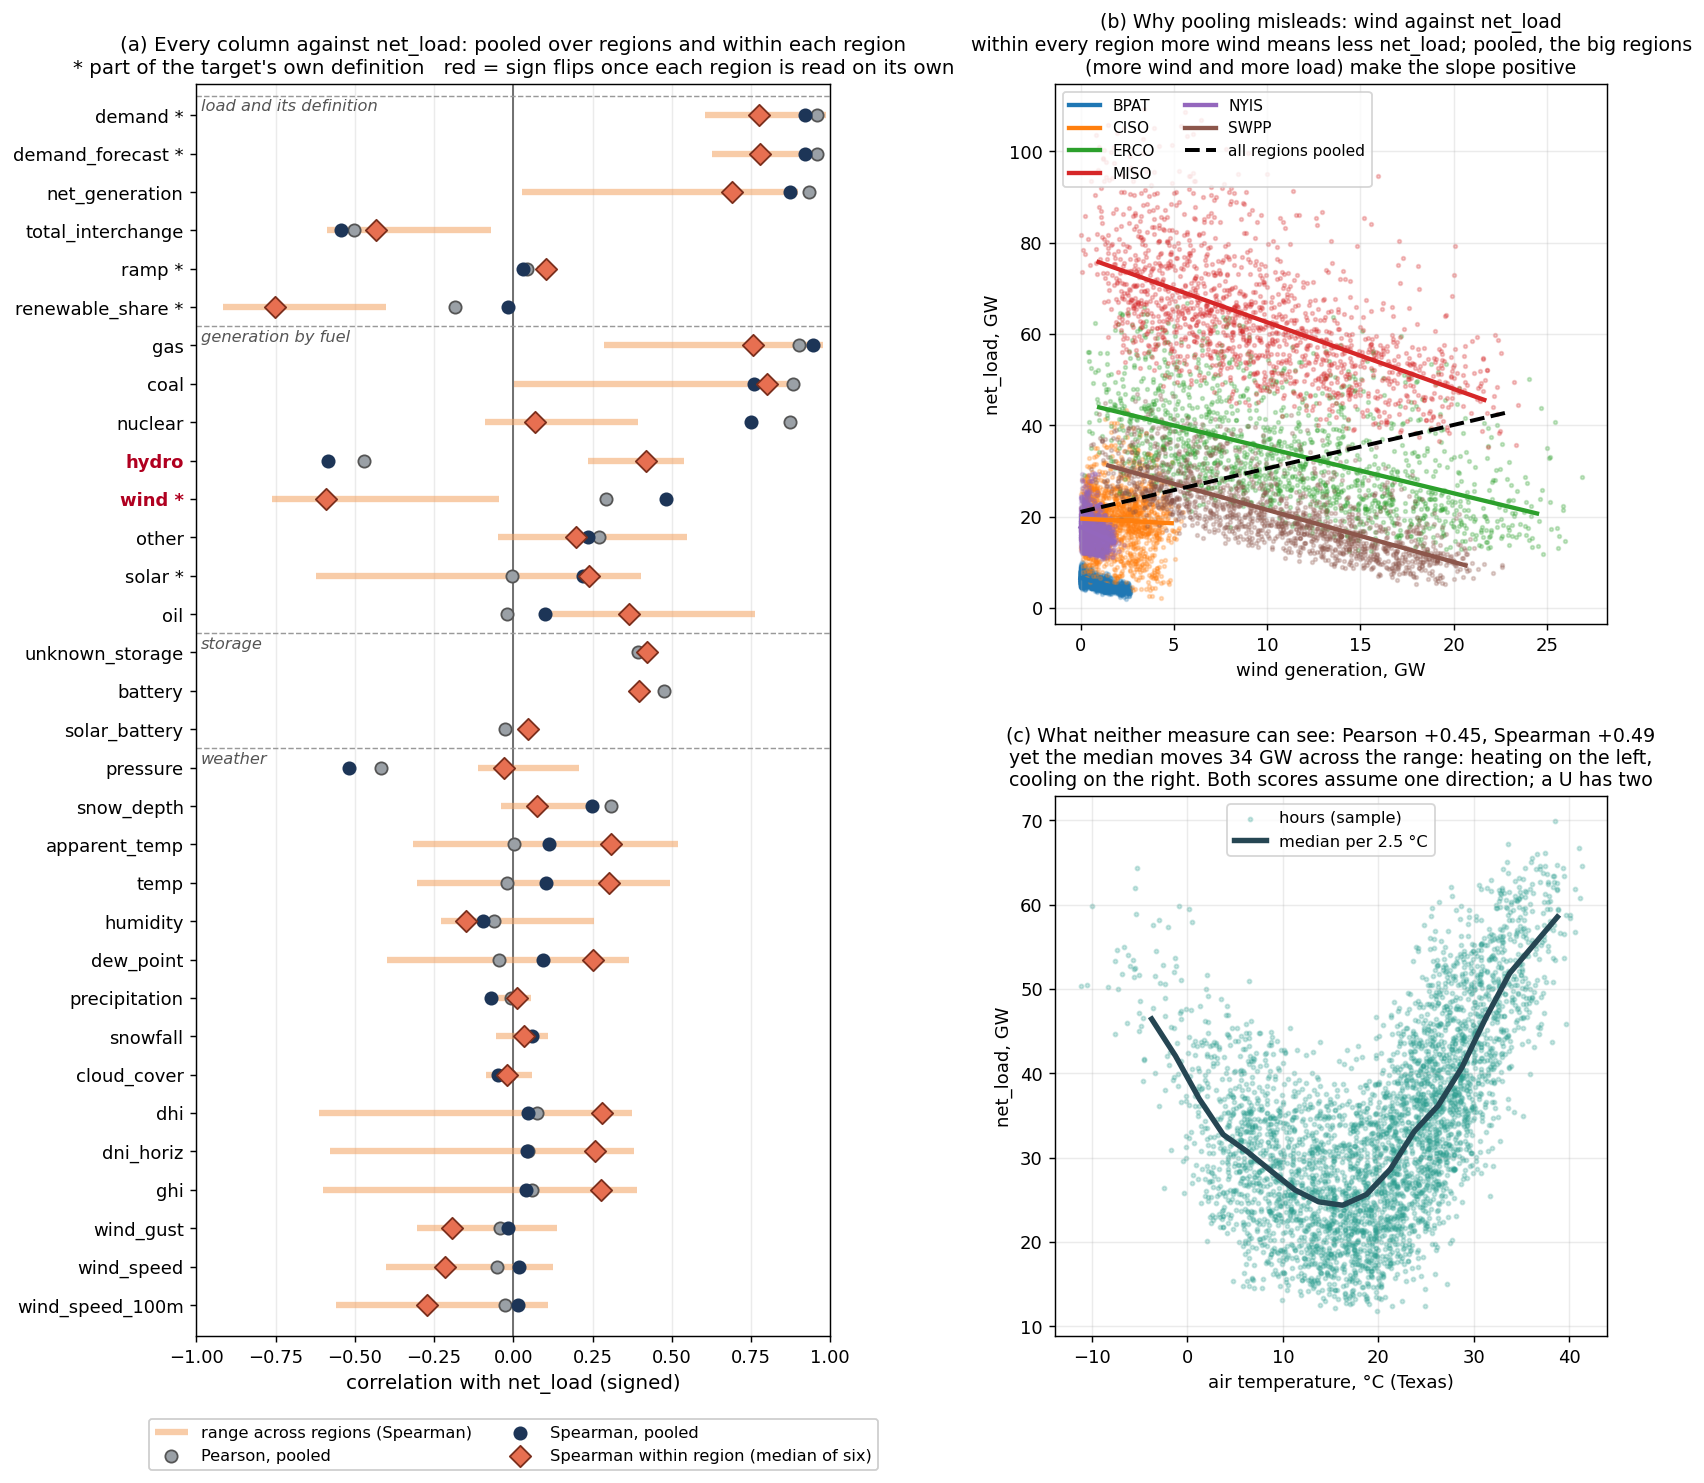


--- every column against the target: pooled, and within each region (signed) ---
    within_* = Spearman computed inside each region; median, min and max of the six
                   pearson  spearman  within_median  within_min  within_max  regions
demand                0.96      0.92           0.78        0.61        0.99        6
demand_forecast       0.96      0.92           0.78        0.63        0.97        6
net_generation        0.93      0.87           0.69        0.03        0.90        6
total_interchange    -0.50     -0.54          -0.43       -0.59       -0.07        6
ramp                  0.04      0.03           0.10        0.08        0.13        6
renewable_share      -0.18     -0.02          -0.75       -0.92       -0.40        6
gas                   0.90      0.95           0.76        0.29        0.98        6
coal                  0.88      0.76           0.80        0.00        0.89        4
nuclear               0.87      0.75           0.07       -0.09      

In [9]:
# WHAT: Pearson and Spearman over every numeric column (01_corr.png), then every column
#       against the target, pooled over the six regions AND within each region
#       (01_corr_target.png), with the values printed so any of them can be quoted.
# WHY:  the panel stacks six grids about ten times apart in size, so a pooled correlation
#       mixes "how a column moves with net load inside a grid" with "which grid the row is
#       in". The within-region column separates the two; panel (b) shows the reversal it
#       finds for wind, panel (c) the U-shape neither measure can see.
num = df.select_dtypes('number')
p, s = num.corr('pearson'), num.corr('spearman')

assoc = pd.DataFrame({'pearson_abs': p[cfg.TARGET].abs(),
                      'spearman_abs': s[cfg.TARGET].abs()}).drop(index=cfg.TARGET)
assoc = assoc.sort_values('spearman_abs', ascending=False)

# Families, in reading order; anything not listed lands at the end.
FAMILIES = {
    'load and its definition': ['net_load', 'demand', 'demand_forecast', 'net_generation',
                                'total_interchange', 'renewable_share', 'ramp'],
    'generation by fuel': ['gas', 'coal', 'nuclear', 'oil', 'hydro', 'wind', 'solar', 'other'],
    'storage': ['battery', 'unknown_storage', 'solar_battery'],
    'weather': ['temp', 'apparent_temp', 'dew_point', 'humidity', 'pressure', 'cloud_cover',
                'precipitation', 'snowfall', 'snow_depth', 'wind_speed', 'wind_speed_100m',
                'wind_gust', 'ghi', 'dni_horiz', 'dhi'],
}
order = [c for cols in FAMILIES.values() for c in cols if c in num.columns]
order += [c for c in num.columns if c not in order]
family_of = {c: f for f, cols in FAMILIES.items() for c in cols}
# net_load's own ingredients, or columns derived from it: their association is arithmetic
DEFINITIONAL = {'demand', 'demand_forecast', 'wind', 'solar', 'ramp', 'renewable_share'}

# ---- 01_corr.png: one matrix, Pearson above the diagonal and Spearman below it
n = len(order)
M = np.where(np.triu(np.ones((n, n), bool), 1), p.loc[order, order].values, s.loc[order, order].values)
np.fill_diagonal(M, np.nan)
fig, ax = plt.subplots(figsize=(12.5, 11))
im = ax.imshow(M, vmin=-1, vmax=1, cmap='RdBu_r', interpolation='nearest')
ax.set_xticks(range(n), order, rotation=90, fontsize=9.5)
ax.set_yticks(range(n), order, fontsize=9.5)
edges = np.cumsum([sum(c in order for c in cols) for cols in FAMILIES.values()])
for e in edges[:-1]:
    ax.axhline(e - 0.5, color='black', lw=1.2); ax.axvline(e - 0.5, color='black', lw=1.2)
start = 0
for fam, e in zip(FAMILIES, edges):
    ax.text(n + 0.6, (start + e - 1) / 2, fam, va='center', ha='left', fontsize=10, fontweight='bold')
    start = e
ax.plot([-0.5, n - 0.5], [-0.5, n - 0.5], color='#444', lw=0.8)
ax.text(0.0, 1.012, 'below the diagonal: Spearman (rank)', transform=ax.transAxes, ha='left',
        va='bottom', fontsize=10.5, fontweight='bold', color='#1d3557')
ax.text(1.0, 1.012, 'above the diagonal: Pearson (linear)', transform=ax.transAxes, ha='right',
        va='bottom', fontsize=10.5, fontweight='bold', color='#555')
cb = fig.colorbar(im, ax=ax, orientation='horizontal', fraction=0.035, pad=0.2, aspect=45)
cb.set_label('correlation: -1 (move in opposite directions) to +1 (move together)', fontsize=10)
ax.set_title('Correlation between every pair of numeric columns, pooled over the six regions;\n'
             'black lines separate the column families', fontsize=12, pad=24)
plt.savefig(cfg.FIGURES / '01_corr.png', bbox_inches='tight'); plt.show()

print('--- association with the target, every numeric column ---')
print(assoc.round(3).to_string())

R.save('nb01', {'target_association': {
    'pearson_abs': {k: float(v) for k, v in assoc['pearson_abs'].items()},
    'spearman_abs': {k: float(v) for k, v in assoc['spearman_abs'].items()},
    'n_numeric_columns': int(num.shape[1]),
}});

# ---- pooled against within each region (signed, so a reversal is visible)
T = cfg.TARGET
within = pd.DataFrame({z: g.select_dtypes('number').corr('spearman')[T] for z, g in df.groupby(cfg.GROUP_COL)})
tab = pd.DataFrame({'pearson': p[T], 'spearman': s[T], 'within_median': within.median(axis=1),
                    'within_min': within.min(axis=1), 'within_max': within.max(axis=1),
                    'regions': within.notna().sum(axis=1)}).drop(index=T)
tab['family'] = [family_of.get(c, 'other') for c in tab.index]
tab['_f'] = tab.family.map({f: i for i, f in enumerate(FAMILIES)})
tab = tab.sort_values(['_f', 'spearman'], key=lambda c: c if c.name == '_f' else -c.abs()).drop(columns='_f')
flip = ((np.sign(tab.spearman) != np.sign(tab.within_median)) & (tab.spearman.abs() >= 0.2)
        & (tab.within_median.abs() >= 0.2))

# the Pearson-Spearman gap inside each region, for every column
gaps = pd.DataFrame({z: (g.select_dtypes('number').corr('spearman')[T].abs()
                         - g.select_dtypes('number').corr('pearson')[T].abs())
                     for z, g in df.groupby(cfg.GROUP_COL)}).drop(index=T)
g_all = gaps.stack()

# Texas, temperature: the U-shape
tx = df[df[cfg.GROUP_COL] == 'ERCO'][['temp', T]].dropna()
tx_bins = pd.cut(tx.temp, np.arange(-30, 50, 2.5))
tx_med = tx.groupby(tx_bins, observed=True)[T].median() / 1000
tx_med = tx_med[tx.groupby(tx_bins, observed=True).size() >= 200]
tx_p, tx_s = tx.corr('pearson').iloc[0, 1], tx.corr('spearman').iloc[0, 1]

# ---- 01_corr_target.png
fig = plt.figure(figsize=(14, 12.5))
gs = fig.add_gridspec(2, 2, width_ratios=[1.15, 1], height_ratios=[1, 1], wspace=0.38, hspace=0.32)
ax = fig.add_subplot(gs[:, 0])
y = np.arange(len(tab))[::-1]
ax.axvline(0, color='#555', lw=0.9)
ax.hlines(y, tab.within_min, tab.within_max, color='#f4a261', lw=3.5, alpha=0.55,
          label='range across regions (Spearman)')
ax.scatter(tab.pearson, y, s=46, color='#9aa0a6', edgecolor='#555', zorder=3, label='Pearson, pooled')
ax.scatter(tab.spearman, y, s=46, color='#1d3557', zorder=4, label='Spearman, pooled')
ax.scatter(tab.within_median, y, s=70, marker='D', color='#e76f51', edgecolor='#7a2e1c', zorder=5,
           label='Spearman within region (median of six)')
ax.set_yticks(y, [f'{c} *' if c in DEFINITIONAL else c for c in tab.index], fontsize=10)
for lab, c in zip(ax.get_yticklabels(), tab.index):
    if flip[c]:
        lab.set_color('#b00020'); lab.set_fontweight('bold')
prev = None
for yy, fam in zip(y, tab.family):
    if fam != prev:
        ax.axhline(yy + 0.5, color='#999', lw=0.8, ls='--')
        ax.text(-0.985, yy + 0.42, fam, fontsize=9, style='italic', va='top', ha='left', color='#555')
        prev = fam
ax.set_xlim(-1, 1); ax.set_ylim(-0.8, len(tab) - 0.2)
ax.set_xlabel(f'correlation with {T} (signed)', fontsize=11)
ax.grid(axis='x', alpha=0.25)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.06), ncol=2, fontsize=9, framealpha=0.95)
ax.set_title(f'(a) Every column against {T}: pooled over regions and within each region\n'
             '* part of the target\'s own definition   red = sign flips once each region is read on its own',
             fontsize=11)

ax2 = fig.add_subplot(gs[0, 1])
colors = plt.get_cmap('tab10')
for i, (z, g) in enumerate(df[[cfg.GROUP_COL, 'wind', T]].dropna().groupby(cfg.GROUP_COL)):
    smp = g.sample(min(len(g), 1500), random_state=0)
    ax2.scatter(smp.wind / 1000, smp[T] / 1000, s=4, alpha=0.25, color=colors(i))
    b, a = np.polyfit(g.wind / 1000, g[T] / 1000, 1)
    xs = np.linspace(g.wind.quantile(0.01), g.wind.quantile(0.99), 20) / 1000
    ax2.plot(xs, a + b * xs, color=colors(i), lw=2.4, label=z)
allw = df[['wind', T]].dropna()
b, a = np.polyfit(allw.wind / 1000, allw[T] / 1000, 1)
xs = np.linspace(0, allw.wind.quantile(0.995), 20) / 1000
ax2.plot(xs, a + b * xs, color='black', lw=2.2, ls='--', label='all regions pooled')
ax2.set_xlabel('wind generation, GW', fontsize=10); ax2.set_ylabel(f'{T}, GW', fontsize=10)
ax2.legend(fontsize=8.5, ncol=2, loc='upper left'); ax2.grid(alpha=0.25)
ax2.set_title(f'(b) Why pooling misleads: wind against {T}\n'
              f'within every region more wind means less {T}; pooled, the big regions\n'
              '(more wind and more load) make the slope positive', fontsize=10.5)

ax3 = fig.add_subplot(gs[1, 1])
smp = tx.sample(4000, random_state=0)
ax3.scatter(smp.temp, smp[T] / 1000, s=5, alpha=0.25, color='#2a9d8f', label='hours (sample)')
ax3.plot([iv.mid for iv in tx_med.index], tx_med.values, color='#264653', lw=3, label='median per 2.5 °C')
ax3.set_xlabel('air temperature, °C (Texas)', fontsize=10); ax3.set_ylabel(f'{T}, GW', fontsize=10)
ax3.legend(fontsize=9, loc='upper center'); ax3.grid(alpha=0.25)
ax3.set_title(f'(c) What neither measure can see: Pearson {tx_p:+.2f}, Spearman {tx_s:+.2f}\n'
              f'yet the median moves {tx_med.max() - tx_med.min():.0f} GW across the range: heating on the left,\n'
              'cooling on the right. Both scores assume one direction; a U has two', fontsize=10.5)
plt.savefig(cfg.FIGURES / '01_corr_target.png', bbox_inches='tight'); plt.show()

print('\n--- every column against the target: pooled, and within each region (signed) ---')
print('    within_* = Spearman computed inside each region; median, min and max of the six')
print(tab.drop(columns='family').round(2).to_string())
print(f'\nsign flips (|pooled| and |within| both >= 0.2, opposite signs): {list(tab.index[flip])}')
print(f'within a region, | |Spearman| - |Pearson| | <= 0.10 for {(g_all.abs() <= 0.10).sum()} of '
      f'{len(g_all)} region-column pairs; largest: {g_all.abs().max():.2f}')
print(f'Texas, temperature against {T}: Pearson {tx_p:+.2f}, Spearman {tx_s:+.2f}; median {T} by 2.5 °C bin '
      f'from {tx_med.min():.1f} GW (at {tx_med.idxmin().mid:.2f} °C) to {tx_med.max():.1f} GW, '
      f'a swing of {tx_med.max() - tx_med.min():.1f} GW')

**Figure: `01_corr.png` — every pair of numeric columns, Pearson above the diagonal and Spearman below.**

**Figure: `01_corr_target.png` — (a) every column against `net_load`, pooled and within region; (b) wind
against net load; (c) temperature against net load in Texas.**

**What I see:**

- One block dominates: `demand` (|r| 0.959), `demand_forecast` (0.959), `net_generation` (0.932), `gas`
  (0.901), `coal` (0.883), `nuclear` (0.874).
- Weather is weak against the target pooled (`temp` 0.020, `ghi` 0.059) but strongly correlated within its
  own block (temperature, apparent temperature and dew point are near-copies).
- Pooling reverses signs. `wind` is +0.48 pooled and −0.59 within regions (panel b); `hydro` goes −0.58 to
  +0.42. `nuclear` falls from 0.75 to 0.07 and `pressure` from −0.52 to −0.03. `renewable_share` goes from
  −0.02 pooled to −0.75 within regions.
- Within a region, Pearson and Spearman differ by at most 0.10 in 161 of 171 pairs (largest gap 0.25).
- Panel (c): in Texas, Pearson is +0.45 and Spearman +0.49, yet median net load falls to 24.3 GW near 16 °C
  and rises to 58.5 GW at the hot end, a swing of 34.2 GW.

**What it means:** The dark block is arithmetic: `net_load = demand − wind − solar`, so the leakage guard
(`MutualInfoSelector.DROP_ALWAYS`) bars same-hour `demand`, `wind`, `solar` and `ramp`. Pooled correlations on
this panel can give the wrong sign. `pressure` and `snow_depth` mostly identify region and season; they stay
in as features but are not weather mechanisms. Pearson–Spearman gaps here mostly reflect region mixing; the
real non-linearity is the U in panel (c), which is why features are ranked on mutual information and the
forecaster is a tree ensemble.

**What I do:** No change to the features: the model already gets the region, selection uses mutual
information, and the leakage guard stays. Any correlation for a fuel or weather column is quoted with its
within-region value.

## Pass 5 — Temporal — *this pass produces the per-horizon lag sets*

### 1.6 — ACF, PACF, and the stationarity pair

ACF and PACF of net load per zone out to 200 lags, ADF and KPSS per zone, then the admissible lag set for
each horizon. Lags are chosen from the PACF, because it measures what a lag adds once all shorter lags are
in; the ACF at lag 168 is mostly inherited through shorter lags. A lag L is observable at forecast origin
t−h only if `L >= h`, so there is one lag set per horizon (h = 1, 24, 48, 72). The PACF needs evenly spaced
data, so each zone's longest contiguous segment is used; BPAT's is the shortest. ADF's null is a unit root;
KPSS's null is stationarity.

--- longest contiguous segment used for ACF / PACF / ADF / KPSS ---
  BPAT: 16,684 h of 52,608 (2019-01-01 -> 2020-11-26)
  CISO: 44,650 h of 52,608 (2019-09-29 -> 2024-11-02)
  ERCO: 52,608 h of 52,608 (2019-01-01 -> 2024-12-31)
  MISO: 48,198 h of 52,608 (2019-01-01 -> 2024-07-01)
  NYIS: 41,659 h of 52,608 (2019-04-18 -> 2024-01-17)
  SWPP: 45,031 h of 52,608 (2019-01-01 -> 2024-02-20)


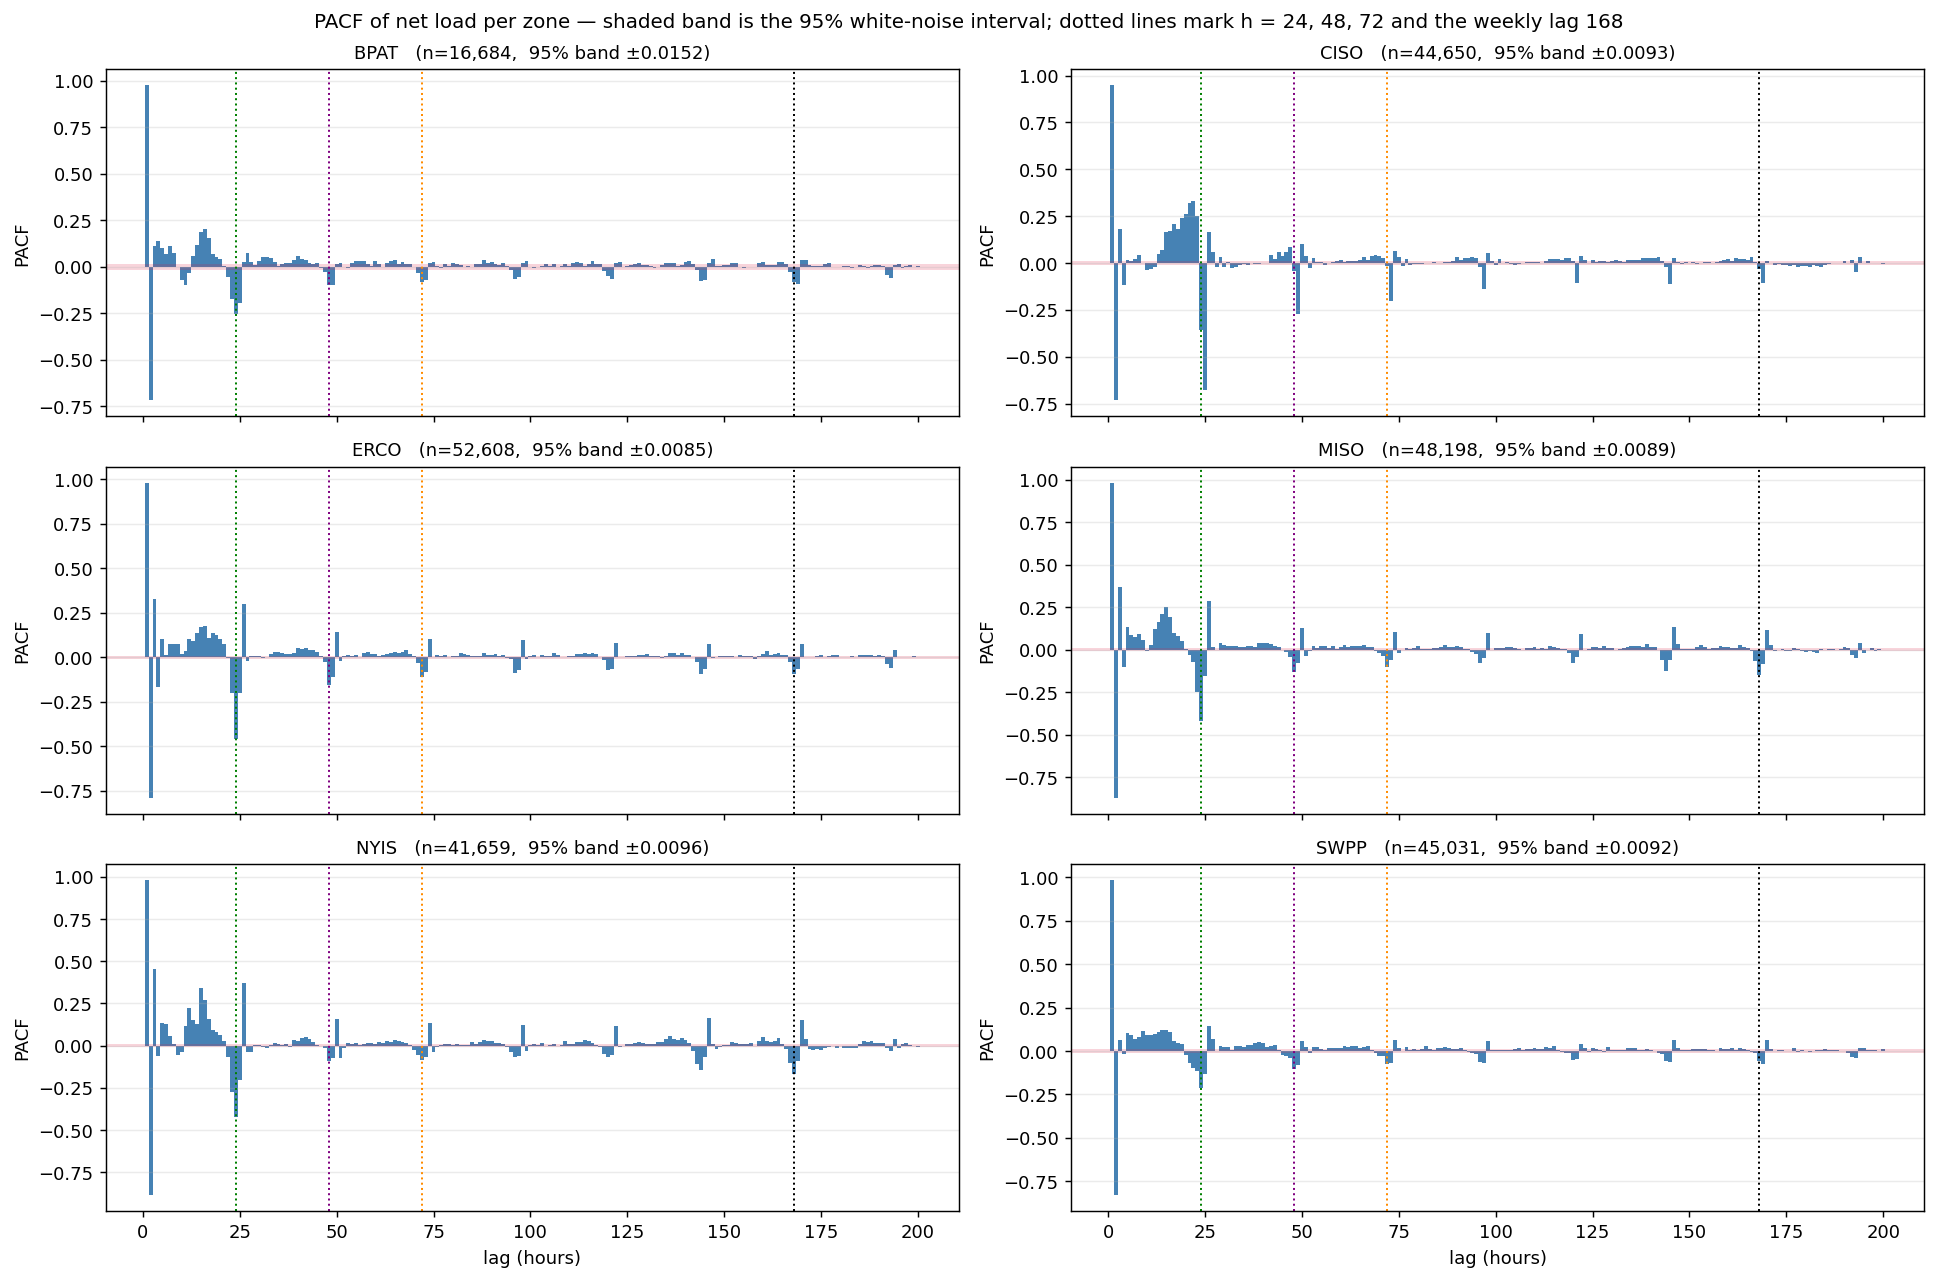

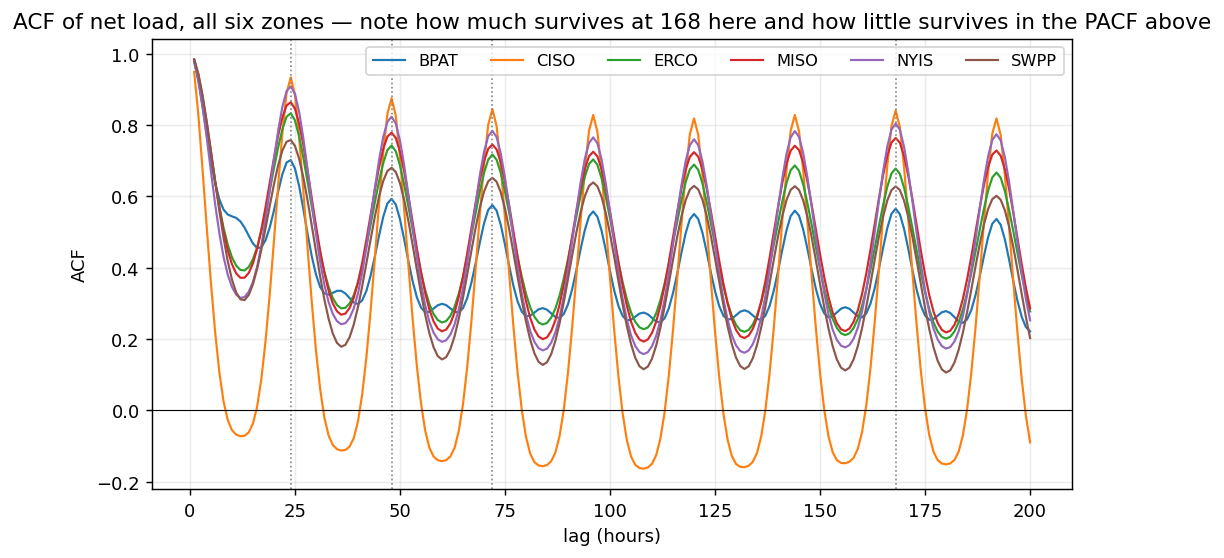

C:\Users\alanm\AppData\Local\Temp\ipykernel_45952\294523541.py:75: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  k = kpss(s.values, regression="c", nlags="auto")


C:\Users\alanm\AppData\Local\Temp\ipykernel_45952\294523541.py:75: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  k = kpss(s.values, regression="c", nlags="auto")


C:\Users\alanm\AppData\Local\Temp\ipykernel_45952\294523541.py:75: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  k = kpss(s.values, regression="c", nlags="auto")



--- ADF (H0: unit root) and KPSS (H0: stationary) on net load, level ---
      adf_stat  adf_p  adf_rejects_unit_root  kpss_stat  kpss_p  kpss_rejects_stationarity
zone                                                                                      
BPAT   -9.3821    0.0                   True     2.8095  0.0100                       True
CISO  -13.1680    0.0                   True     1.0689  0.0100                       True
ERCO  -13.9485    0.0                   True     0.6859  0.0148                       True
MISO  -12.8001    0.0                   True     2.1901  0.0100                       True
NYIS  -10.8964    0.0                   True     0.5047  0.0406                       True
SWPP  -14.2944    0.0                   True     0.5534  0.0296                       True

--- admissible lag sets, one per horizon ---
  h=  1h -> (1, 2, 3, 24, 168)   strongest admissible lag: L1 (mean |PACF| 0.976)
  h= 24h -> (24, 25, 26, 48, 168)   strongest admissible lag: L24 (mea

In [10]:
# WHAT: ACF + PACF per zone, ADF + KPSS per zone, then the admissible lag set per horizon.
# WHY:  this cell produces the deliverable every later notebook consumes. The PACF names the
#       lags carrying INDEPENDENT information; the horizon decides which are observable.
from statsmodels.tsa.stattools import acf, pacf, adfuller, kpss

NLAGS = 200

# --- longest contiguous segment per zone -----------------------------------
# The PACF assumes even spacing. Four 24-hour holes survive the cleaning contract, so
# rather than treat the rows as contiguous we take the longest unbroken run per zone.
segments = {}
for z in zones:
    s = df[df[cfg.GROUP_COL] == z].set_index(cfg.TIME_COL)[cfg.TARGET].sort_index()
    full = s.reindex(pd.date_range(s.index.min(), s.index.max(), freq="h"))
    missing = full.isna().to_numpy()
    best_start = best_len = cur = start = 0
    for i, gap in enumerate(missing):
        if gap:
            cur = 0
        else:
            if cur == 0:
                start = i
            cur += 1
            if cur > best_len:
                best_start, best_len = start, cur
    segments[z] = full.iloc[best_start:best_start + best_len]

print("--- longest contiguous segment used for ACF / PACF / ADF / KPSS ---")
for z, s in segments.items():
    print(f"  {z}: {len(s):>6,} h of 52,608 "
          f"({s.index.min():%Y-%m-%d} -> {s.index.max():%Y-%m-%d})")

# --- ACF and PACF ----------------------------------------------------------
# method='ldb' (Levinson-Durbin on the FFT autocovariance) rather than Yule-Walker:
# same estimand, seconds instead of minutes at 200 lags on ~50k points.
ACF = {z: acf(s.values, nlags=NLAGS, fft=True) for z, s in segments.items()}
PACF = {z: pacf(s.values, nlags=NLAGS, method="ldb") for z, s in segments.items()}
CI = {z: 1.96 / np.sqrt(len(s)) for z, s in segments.items()}

fig, axes = plt.subplots(3, 2, figsize=(15, 10), sharex=True)
for ax, z in zip(axes.ravel(), zones):
    v = PACF[z][1:NLAGS + 1]
    ax.bar(range(1, NLAGS + 1), v, width=1.0, color="steelblue")
    ax.axhspan(-CI[z], CI[z], color="crimson", alpha=.18, lw=0)
    for L, col in ((24, "green"), (48, "purple"), (72, "darkorange"), (168, "black")):
        ax.axvline(L, color=col, ls=":", lw=1.1)
    ax.set_title(f"{z}   (n={len(segments[z]):,},  95% band ±{CI[z]:.4f})", fontsize=10)
    ax.set_ylabel("PACF"); ax.grid(axis="y", alpha=.25)
axes[-1, 0].set_xlabel("lag (hours)"); axes[-1, 1].set_xlabel("lag (hours)")
fig.suptitle("PACF of net load per zone — shaded band is the 95% white-noise interval; "
             "dotted lines mark h = 24, 48, 72 and the weekly lag 168", fontsize=11)
plt.tight_layout()
plt.savefig(cfg.FIGURES / "01_pacf.png", bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(8, 4.4))
for z in zones:
    ax.plot(range(1, NLAGS + 1), ACF[z][1:NLAGS + 1], lw=1.2, label=z)
for L in (24, 48, 72, 168):
    ax.axvline(L, color="grey", ls=":", lw=.9)
ax.axhline(0, lw=.6, color="k")
ax.set_xlabel("lag (hours)"); ax.set_ylabel("ACF")
ax.set_title("ACF of net load, all six zones — note how much survives at 168 here "
             "and how little survives in the PACF above")
ax.legend(ncol=6, fontsize=9); ax.grid(alpha=.25)
plt.tight_layout()
plt.savefig(cfg.FIGURES / "01_acf.png", bbox_inches="tight")
plt.show()

# --- ADF and KPSS ----------------------------------------------------------
# Opposite nulls: ADF H0 = a unit root (non-stationary); KPSS H0 = stationary.
st = []
for z, s in segments.items():
    a = adfuller(s.values, maxlag=48, autolag="AIC", regression="c")
    k = kpss(s.values, regression="c", nlags="auto")
    st.append({"zone": z, "adf_stat": a[0], "adf_p": a[1],
               "adf_rejects_unit_root": a[1] < 0.05,
               "kpss_stat": k[0], "kpss_p": k[1],
               "kpss_rejects_stationarity": k[1] < 0.05})
stat = pd.DataFrame(st).set_index("zone")
print("\n--- ADF (H0: unit root) and KPSS (H0: stationary) on net load, level ---")
print(stat.round(4).to_string())

# --- the admissible lag set per horizon ------------------------------------
mean_abs = np.array([np.mean([abs(PACF[z][L]) for z in zones])
                     for L in range(NLAGS + 1)])
n_sig = np.array([int(sum(abs(PACF[z][L]) > CI[z] for z in zones))
                  for L in range(NLAGS + 1)])


def admissible_set(h):
    # One rule, applied at every horizon: the three freshest observable hours, the next
    # whole-day anchor, and the weekly lag. Constant feature count across horizons, so
    # Notebook 04 compares horizons rather than feature-set sizes.
    block = [h, h + 1, h + 2]
    anchor = next(m for m in range(24, NLAGS + 1, 24) if m >= h and m not in block)
    return tuple(sorted(set(block + [anchor, 168])))


print("\n--- admissible lag sets, one per horizon ---")
lags_by_horizon = {}
ev = []
for h in cfg.HORIZONS:
    chosen = admissible_set(h)
    lags_by_horizon[str(h)] = list(chosen)
    for L in chosen:
        ev.append({"horizon": h, "lag": L, "mean_abs_pacf": round(float(mean_abs[L]), 4),
                   "zones_significant": f"{n_sig[L]}/6"})
    best = max(chosen, key=lambda L: mean_abs[L])
    print(f"  h={h:>3}h -> {chosen}   strongest admissible lag: "
          f"L{best} (mean |PACF| {mean_abs[best]:.3f})")
print("\n--- the evidence behind each choice ---")
print(pd.DataFrame(ev).to_string(index=False))

# The contract, asserted rather than trusted: nothing below the horizon.
for h, lags in lags_by_horizon.items():
    assert min(lags) >= int(h), f"h={h} admitted lag {min(lags)}"
assert {int(k): tuple(v) for k, v in lags_by_horizon.items()} == cfg.LAGS_BY_HORIZON, (
    "the derived lag sets disagree with src/config.py:LAGS_BY_HORIZON")
print("\nOK: every lag set is observable at its own forecast origin, "
      "and config.py agrees with what this cell derived.")

# Every lag named in the interpretation cell below is recorded here, so the prose
# has a source and cannot drift away from the figure it describes.
QUOTED_LAGS = (1, 2, 3, 23, 24, 25, 26, 48, 49, 50, 72, 73, 74, 96, 97, 144, 146, 168, 169)

R.save("nb01", dict(
    horizons=list(cfg.HORIZONS),
    lags_by_horizon=lags_by_horizon,
    chosen_lags=lags_by_horizon["1"],
    pacf_segment_hours={z: int(len(s)) for z, s in segments.items()},
    pacf_mean_abs={str(L): round(float(mean_abs[L]), 4) for L in QUOTED_LAGS},
    pacf_zones_significant={str(L): int(n_sig[L]) for L in QUOTED_LAGS},
    pacf_by_zone={z: {str(L): round(float(PACF[z][L]), 4)
                      for L in (1, 2, 3, 24, 25, 26, 168)} for z in zones},
    stationarity={z: {"adf_p": float(r.adf_p), "kpss_p": float(r.kpss_p)}
                  for z, r in stat.iterrows()},
));
_acf_min = {z: (float(np.min(ACF[z][1:NLAGS + 1])), int(np.argmin(ACF[z][1:NLAGS + 1]) + 1)) for z in ACF}
print(f"\nlowest autocorrelation up to lag {NLAGS}, by zone:")
for _z, (_v, _l) in _acf_min.items():
    print(f"  {_z}: {_v:+.3f} at lag {_l}")

**What I see:** The same shape in every zone. Lag 1 dominates (mean |PACF| 0.976), lag 2 is large and
negative (mean |PACF| 0.805), lag 3 is smaller (0.252), then a daily block around 24 hours (lag 24: 0.355).
After about lag 30 the bars stay near the band; lag 168 is 0.097, below lags 24, 25 (0.262) and 26 (0.215).
CISO's lag 25 (−0.677) is nearly twice its lag 24 (−0.358). The ACF stays high with bumps at every multiple
of 24. ADF and KPSS both reject in all six zones (ADF p = 0.0000; KPSS p between 0.0100 and 0.0406).

**What it means:** Positive lag 1 with negative lag 2 means the model needs the level and the local slope.
The weekly lag is significant in all zones but small: its large ACF is inherited through shorter lags.
Rejecting both ADF and KPSS means no unit root, but not stationary around a constant either, because of the
daily and annual cycles. The fix is calendar features, not differencing. CISO's lag-25 effect fits a solar
system whose trough moves with sunrise.

**What I do:** One rule at every horizon: the three freshest observable hours (h, h+1, h+2), the next
whole-day anchor, and lag 168. This gives `1: (1,2,3,24,168)`, `24: (24,25,26,48,168)`,
`48: (48,49,50,72,168)` and `72: (72,73,74,96,168)`. Lag 168 is kept despite its small PACF: it is
significant in 6/6 zones and at h=72 it is the strongest admissible lag (0.097, above lag 72's 0.079). A
constant feature count lets notebook 04 attribute error changes to the horizon. The strongest admissible lag
falls 0.976 → 0.355 → 0.120 → 0.097 as h goes 1 → 24 → 48 → 72, so error should rise with the horizon, with
the largest jump between h=1 and h=24.

## Pass 6 — Cross-sectional

### 1.7 — Do the zones move together?

Inter-zone correlation of net load, and weekly means on shared axes. This bears on whether one pooled model
with a zone feature is reasonable.

zone,BPAT,CISO,ERCO,MISO,NYIS,SWPP
zone,,,,,,
BPAT,1.00,0.06,0.09,0.22,0.25,0.21
CISO,0.06,1.00,0.16,0.09,0.03,0.05
ERCO,0.09,0.16,1.00,0.73,0.60,0.79
MISO,0.22,0.09,0.73,1.00,0.82,0.83
NYIS,0.25,0.03,0.60,0.82,1.00,0.69
SWPP,0.21,0.05,0.79,0.83,0.69,1.00


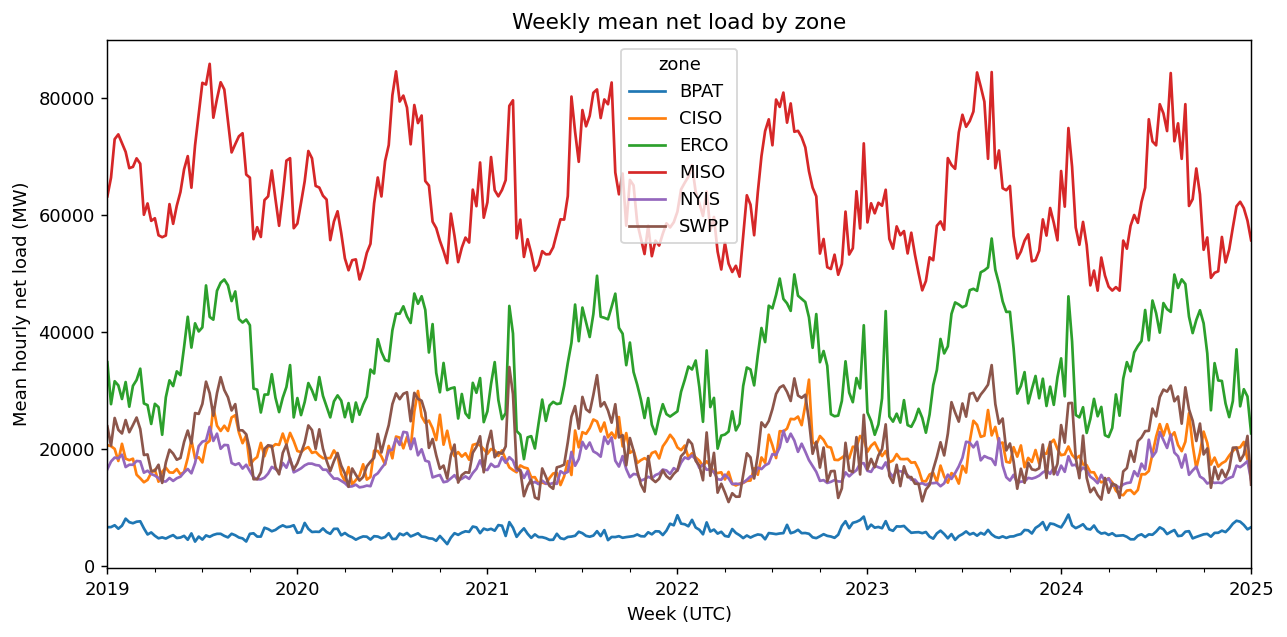

In [11]:
wide = df.pivot_table(index=cfg.TIME_COL, columns=cfg.GROUP_COL, values=cfg.TARGET)
display(wide.corr().round(2))
ax = wide.resample('W').mean().plot(title='Weekly mean net load by zone')
# MW, not MWh: resample().mean() averages hourly power, it does not sum energy.
ax.set_ylabel('Mean hourly net load (MW)')
ax.set_xlabel('Week (UTC)')
plt.tight_layout(); plt.savefig(cfg.FIGURES / '01_zones.png'); plt.show()

**Figure: `01_zones.png` — weekly mean net load by zone across the full window.**

**What I see:** MISO is highest (roughly 47,000–86,000 MW) with a summer peak. ERCO runs roughly
18,000–56,000 MW, with higher summer peaks late in the window (about 56,000 MW in August 2023). CISO, SWPP
and NYIS overlap around 11,000–34,000 MW. BPAT is nearly flat at 4,000–8,000 MW. There is a sharp spike in
ERCO and SWPP in February 2021 and a smaller CISO spike in late summer 2022. MISO, SWPP, ERCO and NYIS
correlate 0.60–0.83; CISO (0.03–0.16) and BPAT (0.06–0.25) barely move with the others.

**What it means:** The zones differ in level, amplitude and peak timing, so a pooled model needs zone
identity. Pooling cannot rest on the zones moving together; it rests on shared structure in how the
features act. The February 2021 spike is Winter Storm Uri, a real extreme that sits in the training period
(the holdout starts 2024-02-07), so the model is never tested on an event like it.

**What I do:** Keep zone identity as a feature and split on the panel. Treat Uri as a named training event,
so a good fit there is not presented as extreme-weather skill.

## Pass 7 — The fuel mix over time

### 1.8 — What is actually generating, and how that changes across six years

Monthly generation by fuel for the six-zone fleet, 2019–2024: absolute (a), shares (b), and the wind + solar
share per zone (c). The project's premise is that net load gets harder to forecast as wind and solar grow;
this checks it. Read trends from (b), since (a) mixes growth with composition. The three storage codes are
excluded (0.4% of rows, starting late 2024). A fuel a zone never reports is a structural zero; a fuel it
stops reporting is left missing, so CISO's 11-month gap shows as a marked dip.

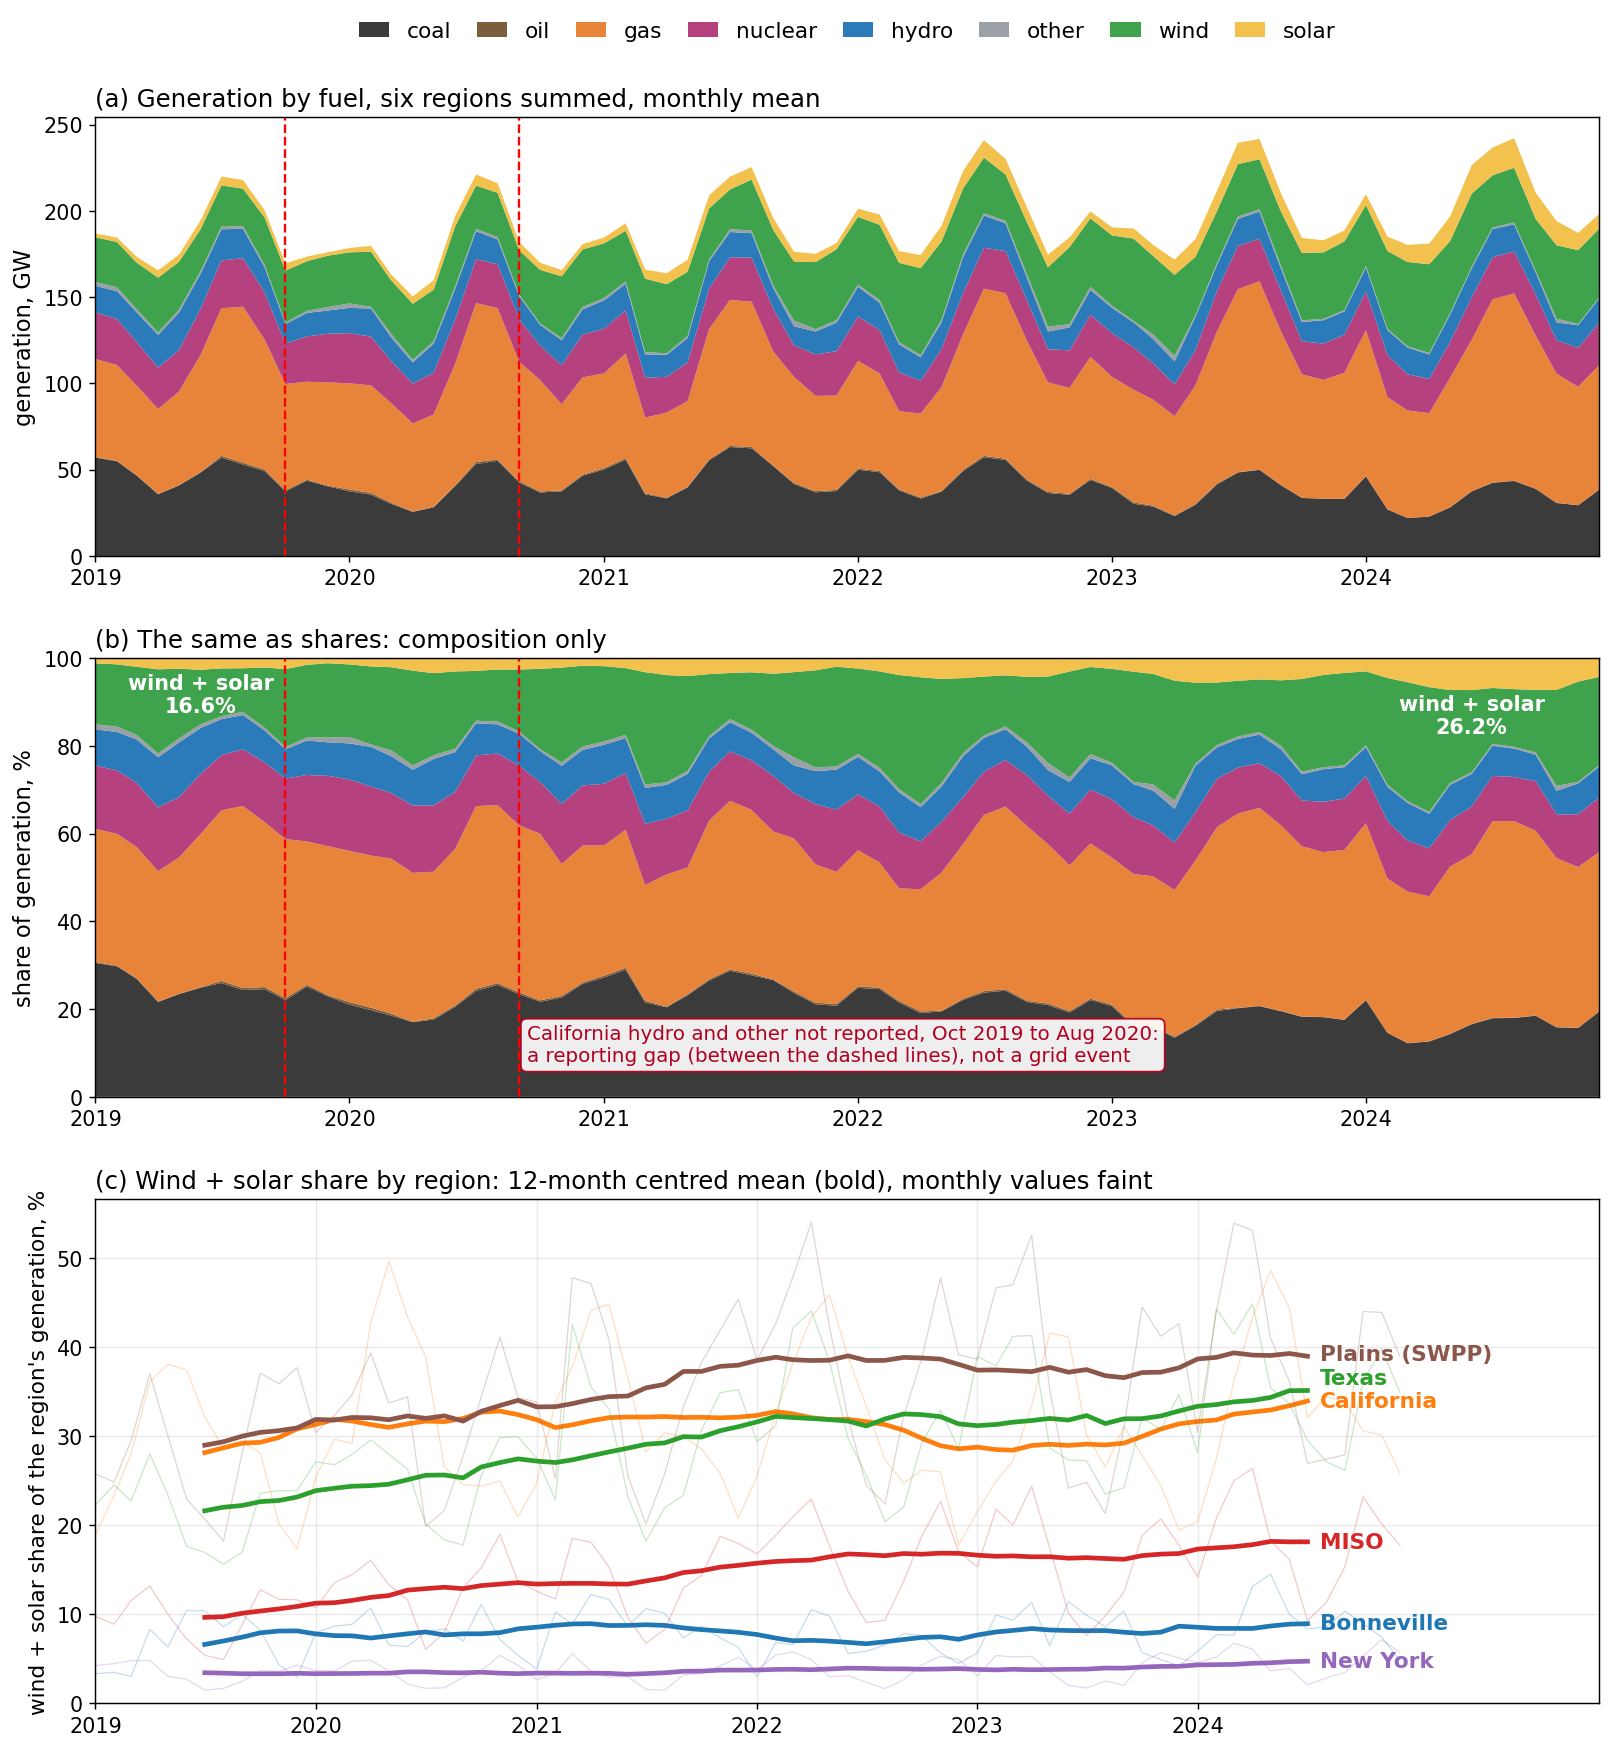

fuel         2019    2024   change
coal        25.7%   16.5%    -9.2 pp
oil          0.3%    0.0%    -0.2 pp
gas         33.2%   38.6%    +5.4 pp
nuclear     14.3%   11.2%    -3.1 pp
hydro        9.1%    7.1%    -2.0 pp
other        0.9%    0.5%    -0.4 pp
wind        15.0%   20.1%    +5.2 pp
solar        1.7%    6.0%    +4.3 pp

wind+solar 16.6% -> 26.2% (+9.5 pp)

wind+solar share by zone, first 12 vs last 12 months:
  BPAT:   6.6% ->   8.9%  ( +2.3 pp)
  CISO:  30.9% ->  33.9%  ( +3.0 pp)
  ERCO:  21.6% ->  35.1%  (+13.5 pp)
  MISO:   9.6% ->  18.1%  ( +8.5 pp)
  NYIS:   3.4% ->   4.7%  ( +1.3 pp)
  SWPP:  29.0% ->  38.9%  (+10.0 pp)
[results read-only] nb01: 1 key(s) verified against the ledger, nothing written


In [12]:
# WHAT: the fleet's generation mix across the full window - absolute, composition,
#       and per zone.
# WHY:  net_load = demand - wind - solar. If wind and solar are not growing, the
#       project's premise is wrong and this is where that would show.
#
# TWO DATA DECISIONS, both defensible out loud:
#   1. The three storage codes are EXCLUDED. battery and unknown_storage are ERCO
#      only from 2024-11; solar_battery is BPAT only from 2024-07; together 0.4%
#      of rows. Stacked, they would draw a new source appearing in late 2024 -
#      an artefact of EIA adding a reporting code, not of the grid changing.
#   2. A fuel a zone NEVER reports is a structural zero (BPAT reports no coal,
#      ERCO no oil). A fuel a zone normally reports and then stops is left MISSING
#      and the affected window is marked, not filled. Filling it would invent
#      generation; dropping the zone would silently change what the total means.
#
# The figure is drawn at the size the final report shows it (Figure 2 there): large
# type, the legend above panel (a), and panel (c)'s lines labelled at their ends.

import matplotlib.dates as mdates

STACK = ["coal", "oil", "gas", "nuclear", "hydro", "other", "wind", "solar"]
FUEL_COLOR = {"coal": "#3b3b3b", "oil": "#7b5e3b", "gas": "#e8833a",
              "nuclear": "#b5417f", "hydro": "#2b7bba", "other": "#9aa0a6",
              "wind": "#3fa34d", "solar": "#f2c14e"}
STORAGE = ["battery", "unknown_storage", "solar_battery"]
ZONE_NAME = {"CISO": "California", "ERCO": "Texas", "MISO": "MISO", "SWPP": "Plains (SWPP)",
             "BPAT": "Bonneville", "NYIS": "New York"}
ZONE_COLOR = {"CISO": "#ff7f0e", "ERCO": "#2ca02c", "MISO": "#d62728", "SWPP": "#8c564b",
              "BPAT": "#1f77b4", "NYIS": "#9467bd"}

d = df.copy()
for f in STACK:
    # a fuel reported in under 1% of a zone's hours (MISO oil: 24 hours) counts as not reported,
    # as in notebook 00; otherwise every MISO hour would count as incomplete below
    reports = d.groupby(cfg.GROUP_COL)[f].transform(lambda s: s.notna().mean() >= 0.01)
    d[f] = d[f].where(reports, 0.0)

# Sum across zones per HOUR, then average over the month: a fleet total, not a
# per-zone average, so the six BAs enter in proportion to their actual size.
mon = d.groupby(cfg.TIME_COL)[STACK].sum(min_count=1).resample("MS").mean() / 1000.0
share = mon.div(mon.sum(axis=1), axis=0) * 100.0

# The contiguous CISO outage, found rather than hardcoded: months >50% missing.
ciso_missing = (d[d[cfg.GROUP_COL] == "CISO"].set_index(cfg.TIME_COL)["hydro"]
                .isna().resample("MS").mean())
blk = ciso_missing[ciso_missing > 0.5]
gap_lo, gap_hi = blk.index.min(), blk.index.max() + pd.offsets.MonthEnd(1)

# 12-month centred rolling: the question is the multi-year trend, and at 3 months
# the seasonal swing (which panels a and b already show) buries it.
ws = {}
for z in zones:
    dz = d[d[cfg.GROUP_COL] == z].set_index(cfg.TIME_COL)[STACK].resample("MS").mean()
    ws[z] = dz[["wind", "solar"]].sum(axis=1) / dz.sum(axis=1) * 100

fig, axes = plt.subplots(3, 1, figsize=(12.5, 13.5), gridspec_kw={"height_ratios": [1, 1, 1.15]})
for ax, data, ylab, title in [
    (axes[0], mon, "generation, GW",
     "(a) Generation by fuel, six regions summed, monthly mean"),
    (axes[1], share, "share of generation, %",
     "(b) The same as shares: composition only"),
]:
    ax.stackplot(data.index, *[data[f] for f in STACK], labels=STACK,
                 colors=[FUEL_COLOR[f] for f in STACK], lw=0)
    ax.set_xlim(data.index.min(), data.index.max())
    ax.set_ylabel(ylab, fontsize=12.5); ax.set_title(title, fontsize=13.5, loc="left")
    ax.tick_params(labelsize=11.5)
    ax.axvline(gap_lo, color="red", ls="--", lw=1.3); ax.axvline(gap_hi, color="red", ls="--", lw=1.3)

axes[0].legend(loc="lower center", bbox_to_anchor=(0.5, 1.13), ncol=8, fontsize=12,
               frameon=False, handlelength=1.4, columnspacing=1.2)
axes[1].set_ylim(0, 100)
axes[1].text(gap_hi + pd.Timedelta(days=12), 8,
             f"California hydro and other not reported, {gap_lo:%b %Y} to {gap_hi:%b %Y}:\n"
             "a reporting gap (between the dashed lines), not a grid event", fontsize=11, color="#b00020",
             bbox=dict(fc="white", ec="#b00020", alpha=0.92, boxstyle="round,pad=0.3"))
# THE HEADLINE SHARES leave out every zone-hour in which a fuel the zone reports is
# missing. The first 12 months run into California's gap (hydro and other unreported
# from November 2019): in those hours its total lacks hydro, and its wind + solar share,
# and the fleet's, would be overstated. The panels above keep the full series and mark
# the gap instead.
_full = d.copy()
_full.loc[_full[STACK].isna().any(axis=1), STACK] = np.nan
mon_c = _full.groupby(cfg.TIME_COL)[STACK].sum(min_count=1).resample("MS").mean() / 1000.0
share_c = mon_c.div(mon_c.sum(axis=1), axis=0) * 100.0
ws_c = {}
for z in zones:
    dz = _full[_full[cfg.GROUP_COL] == z].set_index(cfg.TIME_COL)[STACK].resample("MS").mean()
    ws_c[z] = dz[["wind", "solar"]].sum(axis=1) / dz.sum(axis=1) * 100

# the two ends of the transition, printed on panel (b)
v0 = share_c.iloc[:12][["wind", "solar"]].sum(axis=1).mean()
v1 = share_c.iloc[-12:][["wind", "solar"]].sum(axis=1).mean()
axes[1].annotate(f"wind + solar\n{v0:.1f}%", xy=(share.index[5], 100 - v0 / 2), ha="center",
                 va="center", fontsize=11.5, fontweight="bold", color="white")
axes[1].annotate(f"wind + solar\n{v1:.1f}%", xy=(share.index[-7], 100 - v1 / 2), ha="center",
                 va="center", fontsize=11.5, fontweight="bold", color="white")

ax = axes[2]
ends = {}
for z, s in ws.items():
    col = ZONE_COLOR.get(z)
    ax.plot(s.index, s.values, lw=0.7, alpha=0.25, color=col)
    roll = s.rolling(12, center=True).mean()
    ax.plot(s.index, roll, lw=2.6, color=col)
    last = roll.dropna()
    ends[z] = (last.index[-1], last.iloc[-1])
# label each line at its end, pushed apart where two ends are closer than 2.6 points
ys = sorted(ends, key=lambda z: ends[z][1])
placed = []
for z in ys:
    y = ends[z][1] if not placed else max(ends[z][1], placed[-1] + 2.6)
    placed.append(y)
    ax.text(ends[z][0] + pd.Timedelta(days=20), y, ZONE_NAME.get(z, z), color=ZONE_COLOR.get(z),
            fontsize=12, fontweight="bold", va="center")
ax.set_xlim(mon.index.min(), mon.index.max() + pd.Timedelta(days=330))
ax.set_xticks(pd.date_range(mon.index.min(), mon.index.max(), freq="YS"))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_ylim(0, None)
ax.set_ylabel("wind + solar share of the region's generation, %", fontsize=12)
ax.tick_params(labelsize=11.5)
ax.grid(alpha=0.25)
ax.set_title("(c) Wind + solar share by region: 12-month centred mean (bold), monthly values faint",
             fontsize=13.5, loc="left")
fig.tight_layout(h_pad=2.2)
plt.savefig(cfg.FIGURES / "01_fuel_mix_over_time.png", bbox_inches="tight")
plt.show()

# --- the numbers the interpretation quotes, saved so they are traceable --------
first12, last12 = share_c.index[:12], share_c.index[-12:]
s0, s1 = share_c.loc[first12].mean(), share_c.loc[last12].mean()
zone_ws = {z: [float(s.iloc[:12].mean()), float(s.iloc[-12:].mean())]
           for z, s in ws_c.items()}

print(f"{'fuel':9s} {'2019':>7s} {'2024':>7s} {'change':>8s}")
for f in STACK:
    print(f"{f:9s} {s0[f]:6.1f}% {s1[f]:6.1f}% {s1[f]-s0[f]:+7.1f} pp")
print(f"\nwind+solar {s0[['wind','solar']].sum():.1f}% -> "
      f"{s1[['wind','solar']].sum():.1f}% "
      f"({s1[['wind','solar']].sum()-s0[['wind','solar']].sum():+.1f} pp)")
print("\nwind+solar share by zone, first 12 vs last 12 months:")
for z, (a, b) in zone_ws.items():
    print(f"  {z}: {a:5.1f}% -> {b:5.1f}%  ({b-a:+5.1f} pp)")

R.save("nb01", {"fuel_mix": {
    "share_first12_pct": {f: float(s0[f]) for f in STACK},
    "share_last12_pct": {f: float(s1[f]) for f in STACK},
    "vre_share_first12_pct": float(s0[["wind", "solar"]].sum()),
    "vre_share_last12_pct": float(s1[["wind", "solar"]].sum()),
    "vre_share_by_zone_pct": zone_ws,
    "ciso_gap_months": int(len(blk)),
    "ciso_gap_window": [str(gap_lo.date()), str(gap_hi.date())],
    "storage_cols_excluded": STORAGE,
    "storage_coverage": {c: float(df[c].notna().mean()) for c in STORAGE},
}});

**What I see:** Comparing the first and last twelve months (complete zone-hours only), coal falls 25.7% →
16.5% (−9.2 pp) and wind + solar rises 16.6% → 26.2% (+9.5 pp). Solar more than tripled (1.7 → 6.0); wind
went 15.0 → 20.1. Gas rose 33.2% → 38.6%; nuclear (−3.1 pp) and hydro (−2.0 pp) drift down. By zone, ERCO
(+13.5 pp) and SWPP (+10.0 pp) moved most, MISO +8.5 and CISO +3.0 follow, and NYIS (+1.3 pp) and BPAT
(+2.3 pp) are essentially flat. Within a year the seasonal swing is far larger than the trend.

**What it means:** The premise holds: wind and solar grew by 9.5 points of fleet share in six years. But the
change is concentrated in two zones, so the fleet average is the wrong unit, and comparing periods less
than a year apart measures the season, not the transition.

**What I do:** Report per-zone error in notebook 04 (prediction P4). Do not use CISO `hydro` or `other` in
2019-10 → 2020-08 without saying so; the target is unaffected because `demand`, `wind` and `solar` are
present there. The nuclear decline is a question, not a finding.

## Pass 8 — The weather data

### 1.9 — ERA5: what it is, why this project has it, and how the model uses it

ERA5 is ECMWF's hourly atmospheric reanalysis: a physics model corrected toward historical observations,
on a ~31 km grid. Because it is model output, it has no gaps: all fifteen weather columns are 100.00%
complete, against 83.34% for EIA's `coal`.

Weather drives all three terms of `net_load = demand − wind − solar`:

| term | driver |
|---|---|
| `demand` | `temp`, `apparent_temp`, `dew_point` |
| `wind` | `wind_speed_100m` (hub height) |
| `solar` | `ghi` (and `dni_horiz`, `dhi`), `cloud_cover` |

These fifteen columns (`cfg.WEATHER_FEATURES`) are the only same-hour exogenous features; everything else is
lagged history or calendar. Irradiance is not leakage: it causes solar output but is not a term in the
target, and a weather forecast exists at the forecast origin, whereas realised generation does not. Data
come from Open-Meteo, one population-weighted point per balancing authority, in UTC.

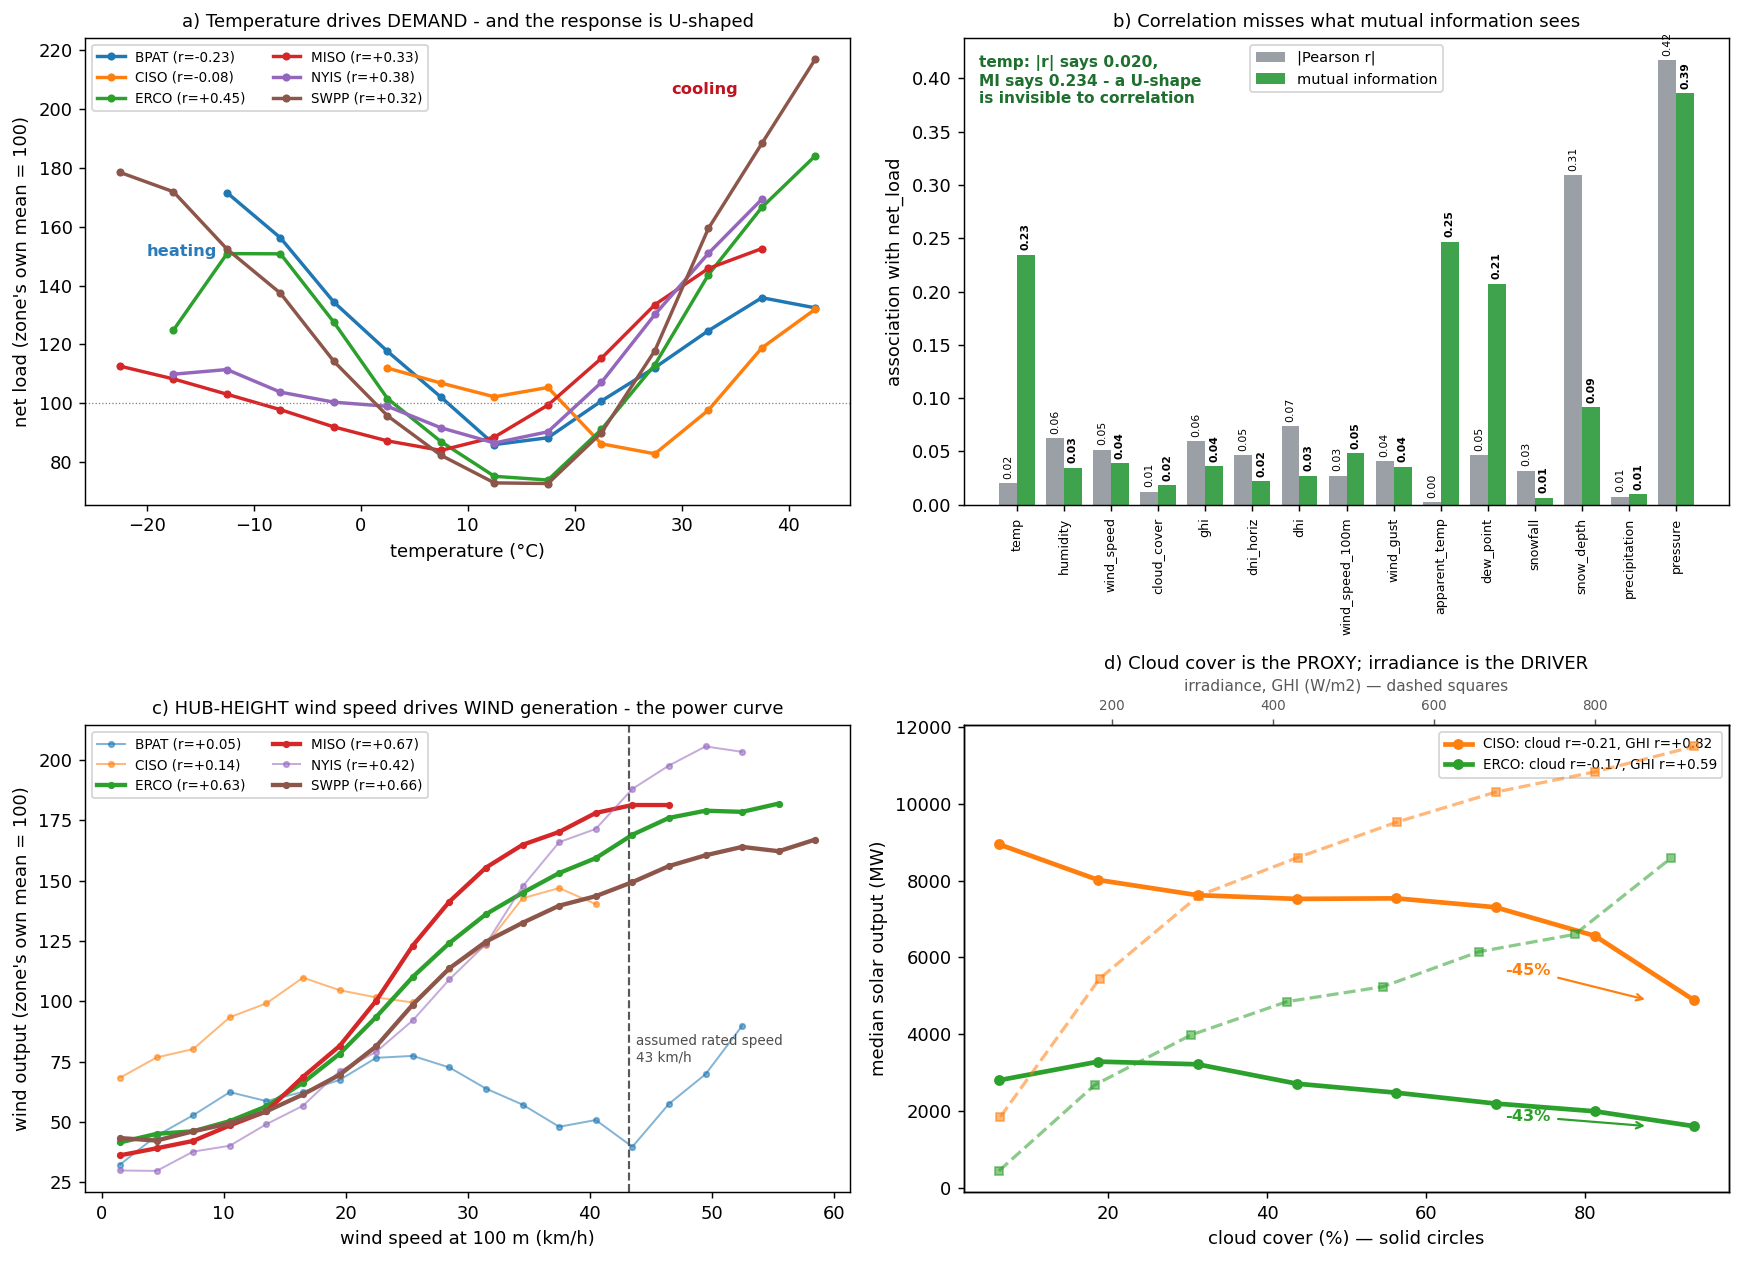

completeness, ERA5 vs a real meter:
  temp         100.00%
  humidity     100.00%
  wind_speed   100.00%
  cloud_cover  100.00%
  ghi          100.00%
  dni_horiz    100.00%
  dhi          100.00%
  wind_speed_100m 100.00%
  wind_gust    100.00%
  apparent_temp 100.00%
  dew_point    100.00%
  snowfall     100.00%
  snow_depth   100.00%
  precipitation 100.00%
  pressure     100.00%
  coal          83.34%

hub height vs 10 m, |Pearson r| of wind speed against wind generation:
  BPAT: 10 m +0.090   100 m +0.054
  CISO: 10 m +0.130   100 m +0.138
  ERCO: 10 m +0.526   100 m +0.634
  MISO: 10 m +0.580   100 m +0.667


  NYIS: 10 m +0.345   100 m +0.420
  SWPP: 10 m +0.566   100 m +0.664

Pearson |r| vs mutual information with net_load:
  temp         |r|=0.020   MI=0.234
  humidity     |r|=0.062   MI=0.035
  wind_speed   |r|=0.052   MI=0.039
  cloud_cover  |r|=0.012   MI=0.018
  ghi          |r|=0.059   MI=0.036
  dni_horiz    |r|=0.046   MI=0.022
  dhi          |r|=0.074   MI=0.027
  wind_speed_100m |r|=0.027   MI=0.048
  wind_gust    |r|=0.041   MI=0.036
  apparent_temp |r|=0.003   MI=0.247
  dew_point    |r|=0.046   MI=0.207
  snowfall     |r|=0.032   MI=0.007
  snow_depth   |r|=0.309   MI=0.091
  precipitation |r|=0.008   MI=0.010
  pressure     |r|=0.417   MI=0.386

temperature response by zone (index, zone mean = 100):
  BPAT: r=-0.229 | cold   172 | min    86 at +12C | hot   132
  CISO: r=-0.079 | cold   112 | min    83 at +28C | hot   132


  ERCO: r=+0.454 | cold   125 | min    74 at +18C | hot   184
  MISO: r=+0.329 | cold   113 | min    84 at +8C | hot   153
  NYIS: r=+0.376 | cold   110 | min    86 at +12C | hot   169
  SWPP: r=+0.319 | cold   179 | min    73 at +18C | hot   217


[results read-only] nb01: 1 key(s) verified against the ledger, nothing written


In [13]:
# WHAT: the ERA5 columns, shown as the physical drivers of the three terms of
#       net_load = demand - wind - solar.
# WIDENED 2026-08-23 from four columns to fifteen. Two panels change substantively,
# and both are the point of the widening rather than decoration:
#   (c) uses wind_speed_100m -- HUB HEIGHT -- rather than the 10 m reading. A
#       turbine does not stand at 10 m, and the r values printed below say how much
#       that mattered.
#   (d) plots solar against IRRADIANCE as well as cloud cover. `cloud_cover` was a
#       proxy for `ghi` all along; now that both are on disk, the figure can show
#       the proxy and the driver side by side instead of assuming they agree.
# WHY:  this is the only exogenous information in the panel. If these relationships
#       are not visible here, the weather features cannot help notebook 04 either, and
#       the ablation in notebook 04 section 4.10 would be measuring noise.
# NOTE: panel (b) is the empirical case for MI over correlation. A correlation filter
#       would rank `apparent_temp` and `temp` near the bottom, although only `pressure`
#       (a zone identifier, see the interpretation) has higher MI.
from sklearn.feature_selection import mutual_info_regression

W = list(cfg.WEATHER_FEATURES)
CZ = dict(zip(zones, plt.cm.tab10(np.linspace(0, 0.55, len(zones)))))
fig, axes = plt.subplots(2, 2, figsize=(13.5, 9.8))

# (a) temperature -> demand: the U-shape, per zone
ax = axes[0, 0]
edges = np.arange(-25, 46, 5)
temp_resp = {}
for z in zones:
    d = df[df[cfg.GROUP_COL] == z]
    b = d.groupby(pd.cut(d["temp"], edges), observed=True)[cfg.TARGET].median().dropna()
    idx = b / d[cfg.TARGET].mean() * 100
    temp_resp[z] = idx
    ax.plot([iv.mid for iv in b.index], idx.values, "o-", ms=3.5, lw=1.9, color=CZ[z],
            label=f"{z} (r={d['temp'].corr(d[cfg.TARGET]):+.2f})")
ax.axhline(100, color="grey", lw=0.7, ls=":")
ax.set_title("a) Temperature drives DEMAND - and the response is U-shaped", fontsize=10)
ax.set_xlabel("temperature (°C)"); ax.set_ylabel("net load (zone's own mean = 100)")
ax.legend(fontsize=7.5, ncol=2)
ax.annotate("heating", xy=(-20, 150), fontsize=9, color="#2b7bba", fontweight="bold")
ax.annotate("cooling", xy=(29, 205), fontsize=9, color="#c1121f", fontweight="bold")

# (b) the methodological point: Pearson vs mutual information
ax = axes[0, 1]
samp = df.sample(30000, random_state=cfg.SEED)
mi = mutual_info_regression(samp[W], samp[cfg.TARGET], random_state=cfg.SEED)
rr = [abs(df[w].corr(df[cfg.TARGET])) for w in W]
x = np.arange(len(W)); wd = 0.38
ax.bar(x - wd/2, rr, wd, label="|Pearson r|", color="#9aa0a6")
ax.bar(x + wd/2, mi, wd, label="mutual information", color="#3fa34d")
for i, (rv, mv) in enumerate(zip(rr, mi)):
    ax.text(i - wd/2, rv + 0.006, f"{rv:.2f}", ha="center", fontsize=6, rotation=90)
    ax.text(i + wd/2, mv + 0.006, f"{mv:.2f}", ha="center", fontsize=6, rotation=90,
            fontweight="bold")
ax.set_xticks(x); ax.set_xticklabels(W, fontsize=7, rotation=90)
ax.set_title("b) Correlation misses what mutual information sees", fontsize=10)
ax.set_ylabel("association with net_load"); ax.legend(fontsize=8)
_ti = W.index("temp")
ax.annotate(f"temp: |r| says {rr[_ti]:.3f},\nMI says {mi[_ti]:.3f} - a U-shape\n"
            f"is invisible to correlation",
            xy=(0.02, 0.86), xycoords="axes fraction", fontsize=8.5,
            color="#1f6f2f", fontweight="bold")

# (c) wind speed -> wind generation
ax = axes[1, 0]
we = np.arange(0, 76, 3.0)     # 100 m wind runs faster than 10 m; the old top
                              # bin at 45 km/h would clip the whole rated region
for z in zones:
    d = df[df[cfg.GROUP_COL] == z]
    # Bins holding few hours draw noise as though it were a power curve: BPAT's top
    # bin spiked to 290 on a handful of hours. Require 100 hours to plot a point.
    grp = d.groupby(pd.cut(d["wind_speed_100m"], we), observed=True)["wind"]
    b = grp.median()[grp.count() >= 100].dropna()
    big = d["wind"].mean() > 5000
    ax.plot([iv.mid for iv in b.index], b.values / d["wind"].mean() * 100, "o-", ms=3,
            color=CZ[z], lw=2.4 if big else 1.1, alpha=1.0 if big else 0.55,
            label=f"{z} (r={d['wind_speed_100m'].corr(d['wind']):+.2f})")
ax.axvline(cfg.WIND_RATED_KMH, color="0.35", ls="--", lw=1.2)
ax.text(cfg.WIND_RATED_KMH + 0.6, ax.get_ylim()[1] * 0.35,
        f"assumed rated speed\n{cfg.WIND_RATED_KMH:.0f} km/h", fontsize=7.5, color="0.3")
ax.set_title("c) HUB-HEIGHT wind speed drives WIND generation - the power curve",
             fontsize=10)
ax.set_xlabel("wind speed at 100 m (km/h)")
ax.set_ylabel("wind output (zone's own mean = 100)"); ax.legend(fontsize=7.5, ncol=2)

# (d) cloud cover -> solar generation
ax = axes[1, 1]
day = df[df["solar"] > 0]
ce = [0, 12.5, 25, 37.5, 50, 62.5, 75, 87.5, 100]
cloud_drop, solar_r = {}, {}
for z in ["CISO", "ERCO"]:
    d = day[day[cfg.GROUP_COL] == z]
    b = d.groupby(pd.cut(d["cloud_cover"], ce), observed=True)["solar"].median().dropna()
    cloud_drop[z] = float((1 - b.iloc[-1] / b.iloc[0]) * 100)
    solar_r[z] = {"cloud_cover": float(d["cloud_cover"].corr(d["solar"])),
                  "ghi": float(d["ghi"].corr(d["solar"])),
                  "clearsky_proxy": float(d["dhi"].corr(d["solar"]))}
    ax.plot([iv.mid for iv in b.index], b.values, "o-", ms=5, lw=2.6, color=CZ[z],
            label=f"{z}: cloud r={solar_r[z]['cloud_cover']:+.2f}, "
                  f"GHI r={solar_r[z]['ghi']:+.2f}")
    ax.annotate(f"-{cloud_drop[z]:.0f}%", xy=(88, b.iloc[-1]), xytext=(70, b.iloc[0]*0.62),
                fontsize=9, color=CZ[z], fontweight="bold",
                arrowprops=dict(arrowstyle="->", color=CZ[z], lw=1.2))
# THE PROXY AND THE DRIVER, side by side. Until 2026-08-23 only cloud cover was on
# disk, so the solar leg of net load was modelled through a summary of the thing
# that actually causes it. If the GHI correlation is materially stronger than the
# cloud one, that gap is the size of the approximation the project was carrying.
ax2 = ax.twiny()
for z in ["CISO", "ERCO"]:
    d = day[day[cfg.GROUP_COL] == z]
    ge = np.linspace(0, d["ghi"].quantile(0.995), 9)
    bg = d.groupby(pd.cut(d["ghi"], ge), observed=True)["solar"].median().dropna()
    ax2.plot([iv.mid for iv in bg.index], bg.values, "s--", ms=4, lw=1.8,
             color=CZ[z], alpha=0.55)
ax2.set_xlabel("irradiance, GHI (W/m2) — dashed squares", fontsize=8.5, color="0.35")
ax2.tick_params(axis="x", labelsize=7.5, colors="0.35")
ax.set_title("d) Cloud cover is the PROXY; irradiance is the DRIVER", fontsize=10)
ax.set_xlabel("cloud cover (%) — solid circles")
ax.set_ylabel("median solar output (MW)")
ax.legend(fontsize=7.5, loc="upper right")

plt.tight_layout()
plt.savefig(cfg.FIGURES / "01_era5_weather.png", bbox_inches="tight")
plt.show()

print("completeness, ERA5 vs a real meter:")
for c in W + ["coal"]:
    print(f"  {c:12s} {df[c].notna().mean()*100:6.2f}%")
print("\nhub height vs 10 m, |Pearson r| of wind speed against wind generation:")
for z in zones:
    d = df[df[cfg.GROUP_COL] == z]
    print(f"  {z}: 10 m {d['wind_speed'].corr(d['wind']):+.3f}   "
          f"100 m {d['wind_speed_100m'].corr(d['wind']):+.3f}")

print("\nPearson |r| vs mutual information with net_load:")
for w, rv, mv in zip(W, rr, mi):
    print(f"  {w:12s} |r|={rv:.3f}   MI={mv:.3f}")
print("\ntemperature response by zone (index, zone mean = 100):")
for z, idx in temp_resp.items():
    print(f"  {z}: r={df[df[cfg.GROUP_COL]==z]['temp'].corr(df[df[cfg.GROUP_COL]==z][cfg.TARGET]):+.3f}"
          f" | cold {idx.iloc[0]:5.0f} | min {idx.min():5.0f} at {idx.idxmin().mid:+.0f}C"
          f" | hot {idx.iloc[-1]:5.0f}")

R.save("nb01", {"era5": {
    "coverage_pct": {c: float(df[c].notna().mean() * 100) for c in W},
    "coal_coverage_pct": float(df["coal"].notna().mean() * 100),
    "pearson_abs": {w: float(v) for w, v in zip(W, rr)},
    "mutual_info": {w: float(v) for w, v in zip(W, mi)},
    "temp_pearson_by_zone": {z: float(df[df[cfg.GROUP_COL] == z]["temp"]
                                      .corr(df[df[cfg.GROUP_COL] == z][cfg.TARGET])) for z in zones},
    "temp_response_index": {z: {"cold": float(i.iloc[0]), "min": float(i.min()),
                                "min_at_c": float(i.idxmin().mid), "hot": float(i.iloc[-1])}
                            for z, i in temp_resp.items()},
    "windspeed_wind_pearson_by_zone": {z: float(df[df[cfg.GROUP_COL] == z]["wind_speed"]
                                                .corr(df[df[cfg.GROUP_COL] == z]["wind"])) for z in zones},
    "windspeed100m_wind_pearson_by_zone": {z: float(df[df[cfg.GROUP_COL] == z]["wind_speed_100m"]
                                                    .corr(df[df[cfg.GROUP_COL] == z]["wind"])) for z in zones},
    "solar_drop_clear_to_overcast_pct": cloud_drop,
    "solar_association_proxy_vs_driver": solar_r,
}});

**What this shows:** (a) net load by 5 °C temperature bin, each zone indexed to its own mean; (b) |Pearson r|
against mutual information for the fifteen weather columns; (c) wind output by hub-height wind speed;
(d) median solar output against cloud cover and against irradiance, daylight hours, CISO and ERCO.

**What I see:** (a) is a U in every zone: SWPP bottoms at 73 around 18 °C and reaches 179 cold and 217 hot;
BPAT is 172 cold against 132 hot. Per-zone correlations have opposite signs (BPAT −0.23, ERCO +0.45) and
cancel to −0.020 pooled. (b) `apparent_temp` has MI 0.247 but |r| 0.003; `temp` 0.234, `dew_point` 0.207.
`pressure` has the highest MI (0.386). `ghi` (0.036) is double `cloud_cover` (0.018). (c) Hub-height wind
beats the 10 m reading in five of six zones (ERCO +0.526 → +0.634, MISO +0.580 → +0.667, SWPP +0.566 →
+0.664); only BPAT gets worse (+0.090 → +0.054). (d) CISO's median solar drops 45% from clear to overcast,
ERCO's 43%.

**What it means:** Each term of net load has a visible weather driver. A correlation filter would rank
`apparent_temp` last and delete it, which is the case for mutual information. `pressure`'s high MI reflects
the elevation of each zone's weather point, so it acts as a zone identifier, not a weather signal; the
same applies to `snow_depth` with a season attached. BPAT's worse hub-height result reflects its weather
point (Portland) being far from its turbines; one point per zone is a limitation.

**What I do:** Keep all fifteen columns; the tuned model keeps every column (`select__k = "all"`), and their
importance is read in notebook 07. Expect weather to matter most at long horizons (prediction P5). ERA5 is
a reanalysis, so it is better than a real forecast; notebook 06 re-scores the holdout on archived forecasts,
which are off by 1.35, 1.95 and 2.09 °C in temperature at one, two and three days.

## 1.10 — Close: five testable predictions

Five predictions, each grounded in a number above, written before any model runs so notebook 04 can mark
them right or wrong.

In [14]:
# WHAT: the five predictions notebook 04 will check, and the notebook 01 hand-off.
# WHY:  written now, before any model exists, so that "we predicted this" is verifiable
#       from results.json rather than asserted after the fact.
predictions = [
    # Grounded in the PACF collapse: mean |PACF| of the strongest ADMISSIBLE lag falls
    # 0.976 (h=1) -> 0.349 (h=24) -> 0.118 (h=48, L49) -> 0.095 (h=72, L168).
    "P1: holdout MAE rises monotonically with the horizon, and the h=1 -> h=24 step is "
    "the largest single jump of the three",
    # At h<=24 lag 24/25 outrank lag 168 in the PACF (0.349 / 0.256 vs 0.095); at h=72
    # lag 168 (0.095) is the strongest admissible lag in the panel.
    "P2: lag168 ranks below the daily anchor in permutation importance at h=1 and h=24, "
    "and above it at h=72 -- the crossover is the finding, not the ranking",
    # Ramp kurtosis 3.71 (BPAT) to 4.46 (SWPP): the ramp tails are heavy, and the
    # duck's steepest rise is CISO's evening ramp (notebook 00, figure 8).
    "P3: MAE is worst in the evening ramp hours (17-21 local) at every horizon",
    # SWPP 34.6% wind+solar vs NYIS 3.7% (notebook 00, figure 00_raw_fuel_mix.png).
    "P4: scaled error (MAE / mean net load) is highest for SWPP and lowest for NYIS",
    # Lag information decays with h; the weather forecast does not.
    "P5: temperature's share of permutation importance rises with the horizon",
]
for p in predictions:
    print(" -", p)

R.save("nb01", dict(predictions=predictions))

res = R.load()["nb01"]
print("\n--- notebook 01 hand-off ---")
print(f"rows_clean         : {res['rows_clean']:,}")
print(f"horizons           : {res['horizons']}")
print(f"lags_by_horizon    : {res['lags_by_horizon']}")
print(f"outlier_decision   : {res['outlier_decision']}")
print(f"predictions        : {len(res['predictions'])}")
print("\nnotebook 02 reads `lags_by_horizon` and builds ONE pipeline per horizon.")
print("Its rolling windows end at the forecast origin t-h, not at t-1 -- see the note in")
print("src/config.py:ROLL_WINDOWS (GroupLagFeatures._roll_shift, fixed in notebook 04).")
print("\nnotebook 01 complete")


 - P1: holdout MAE rises monotonically with the horizon, and the h=1 -> h=24 step is the largest single jump of the three
 - P2: lag168 ranks below the daily anchor in permutation importance at h=1 and h=24, and above it at h=72 -- the crossover is the finding, not the ranking
 - P3: MAE is worst in the evening ramp hours (17-21 local) at every horizon
 - P4: scaled error (MAE / mean net load) is highest for SWPP and lowest for NYIS
 - P5: temperature's share of permutation importance rises with the horizon
[results read-only] nb01: 1 key(s) verified against the ledger, nothing written

--- notebook 01 hand-off ---
rows_clean         : 315,485
horizons           : [1, 24, 48, 72]
lags_by_horizon    : {'1': [1, 2, 3, 24, 168], '24': [24, 25, 26, 48, 168], '48': [48, 49, 50, 72, 168], '72': [72, 73, 74, 96, 168]}
outlier_decision   : {'net_load': 'keep', 'ramp': 'keep', 'renewable_share': 'keep', 'temp': 'keep'}
predictions        : 5

notebook 02 reads `lags_by_horizon` and builds ONE p